
**Name:** Nishtha Lalit Joshi
**Github username** joshinishtha99
**USC ID**  4515720287

## 1. Time Series Classification Part 1

### 1(a) Downloading and Understanding the Dataset

The AReM dataset was downloaded.
It contains seven folders corresponding to the activities bending1, bending2,
cycling, lying, sitting, standing, and walking.

Each CSV file represents one instance of a human performing an activity. Each
instance contains six time series, and each time series contains 480 consecutive
measurements.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.feature_selection import RFECV
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)


In [2]:
data_path = Path("arem_data/AReM")

if not data_path.exists():
    raise FileNotFoundError(
        f"AReM dataset was not found at: {data_path.resolve()}"
    )

print("Dataset found at:", data_path)

Dataset found at: arem_data/AReM


### 1(b) Train and Test Data

Datasets 1 and 2 from the bending1 and bending2 folders are assigned to the
test set. Datasets 1, 2, and 3 from the remaining folders are assigned to the
test set. All other datasets are assigned to the training set.

Therefore, the test set contains 19 instances and the training set contains
69 instances.

In [3]:
activities = [
    "bending1",
    "bending2",
    "cycling",
    "lying",
    "sitting",
    "standing",
    "walking"
]

column_names = [
    "time",
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23"
]

In [4]:
def dataset_number(file):
    match = re.search(r"dataset(\d+)", file.stem)

    if match is None:
        raise ValueError(f"Unexpected filename: {file.name}")

    return int(match.group(1))

In [5]:
def assign_split(activity, number):
    if activity in ["bending1", "bending2"]:
        if number in [1, 2]:
            return "test"
        return "train"

    if number in [1, 2, 3]:
        return "test"

    return "train"

In [6]:
def read_file(file):
    rows = []

    with open(file, "r") as source:
        for line in source:
            line = line.strip()

            if not line or line.startswith("#"):
                continue

            line = line.rstrip(",")

            values = re.split(r"\s*,\s*|\s+", line)

            if len(values) == 7:
                rows.append(values)

    frame = pd.DataFrame(
        rows,
        columns=column_names
    )

    frame = frame.apply(
        pd.to_numeric,
        errors="coerce"
    )

    frame = frame.dropna()

    frame = frame.drop_duplicates(subset="time")


    expected_time = np.arange(
        start=0,
        stop=120000,
        step=250
    )

    frame = frame.set_index("time")
    frame = frame.reindex(expected_time)

    sensor_columns = column_names[1:]

    frame[sensor_columns] = frame[sensor_columns].interpolate(
        method="linear",
        limit_direction="both"
    )

    frame.index.name = "time"
    frame = frame.reset_index()

    return frame

In [7]:
file_records = []

for activity in activities:
    folder = data_path / activity

    files = sorted(
        folder.glob("dataset*.csv"),
        key=dataset_number
    )

    for file in files:
        number = dataset_number(file)
        frame = read_file(file)

        file_records.append({
            "activity": activity,
            "dataset": number,
            "split": assign_split(activity, number),
            "observations": len(frame),
            "file": file
        })

file_check = pd.DataFrame(file_records)

print("Total instances:", len(file_check))
print()
print(file_check["activity"].value_counts())
print()
print(file_check["split"].value_counts())
print()
print(file_check["observations"].value_counts())

Total instances: 88

activity
cycling     15
lying       15
sitting     15
standing    15
walking     15
bending1     7
bending2     6
Name: count, dtype: int64

split
train    69
test     19
Name: count, dtype: int64

observations
480    88
Name: count, dtype: int64


#### 1(c)(ii) Extraction of the Required Features

For each of the six time series in every instance, the following seven
features are extracted: minimum, maximum, mean, median, standard deviation,
first quartile, and third quartile.

Thus, each instance is represented using \(6 \times 7 = 42\) features.

In [8]:
def calculate_stats(frame):
    result = {}

    sensor_columns = column_names[1:]

    for number, column in enumerate(sensor_columns, start=1):
        values = frame[column]

        result[f"min{number}"] = values.min()
        result[f"max{number}"] = values.max()
        result[f"mean{number}"] = values.mean()
        result[f"median{number}"] = values.median()
        result[f"std{number}"] = values.std(ddof=1)
        result[f"1st_quart{number}"] = values.quantile(0.25)
        result[f"3rd_quart{number}"] = values.quantile(0.75)

    return result

In [9]:
rows = []

for activity in activities:
    folder = data_path / activity

    files = sorted(
        folder.glob("dataset*.csv"),
        key=dataset_number
    )

    for file in files:
        number = dataset_number(file)
        frame = read_file(file)
        summary = calculate_stats(frame)

        summary["instance"] = f"{activity}_dataset{number}"
        summary["activity"] = activity
        summary["dataset"] = number
        summary["split"] = assign_split(activity, number)

        rows.append(summary)

features = pd.DataFrame(rows)

print("Number of instances:", len(features))

Number of instances: 88


In [10]:
statistics = [
    "min",
    "max",
    "mean",
    "median",
    "std",
    "1st_quart",
    "3rd_quart"
]

feature_names = []

for series in range(1, 7):
    for statistic in statistics:
        feature_names.append(f"{statistic}{series}")

features = features[
    ["instance", "activity", "dataset", "split"] + feature_names
]

features = features.sort_values(
    ["activity", "dataset"]
).reset_index(drop=True)

features.head()

,instance,activity,dataset,split,min1,max1,mean1,median1,std1,1st_quart1,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
0,bending1_dataset1,bending1,1,test,37.25,45.00,40.624792,40.50,1.476967,39.25,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
1,bending1_dataset2,bending1,2,test,38.00,45.67,42.812812,42.50,1.435550,42.00,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
2,bending1_dataset3,bending1,3,train,35.00,47.40,43.954500,44.33,1.558835,43.00,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
3,bending1_dataset4,bending1,4,train,33.00,47.75,42.179812,43.50,3.670666,39.15,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
4,bending1_dataset5,bending1,5,train,33.00,45.75,41.678063,41.75,2.243490,41.33,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


In [11]:
feature_table = features[
    ["instance"] + feature_names
]

print("Table shape:", feature_table.shape)

feature_table

Table shape: (88, 43)


,instance,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
0,bending1_dataset1,37.25,45.00,40.624792,40.50,1.476967,39.25,42.0000,0.0,1.30,...,2.188449,33.0000,36.00,0.00,1.92,0.570583,0.43,0.582915,0.0000,1.3000
1,bending1_dataset2,38.00,45.67,42.812812,42.50,1.435550,42.00,43.6700,0.0,1.22,...,1.995255,32.0000,34.50,0.00,3.11,0.571083,0.43,0.601010,0.0000,1.3000
2,bending1_dataset3,35.00,47.40,43.954500,44.33,1.558835,43.00,45.0000,0.0,1.70,...,1.999604,35.3625,36.50,0.00,1.79,0.493292,0.43,0.513506,0.0000,0.9400
3,bending1_dataset4,33.00,47.75,42.179812,43.50,3.670666,39.15,45.0000,0.0,3.00,...,3.849448,30.4575,36.33,0.00,2.18,0.613521,0.50,0.524317,0.0000,1.0000
4,bending1_dataset5,33.00,45.75,41.678063,41.75,2.243490,41.33,42.7500,0.0,2.83,...,2.411026,28.4575,31.25,0.00,1.79,0.383292,0.43,0.389164,0.0000,0.5000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,walking_dataset11,19.50,45.33,33.586875,34.25,4.650935,30.25,37.0000,0.0,14.67,...,3.283983,13.7300,18.25,0.00,8.32,3.259729,3.11,1.640243,2.0500,4.3225
84,walking_dataset12,19.75,45.50,34.322750,35.25,4.752477,31.00,38.0000,0.0,13.47,...,3.119856,13.5000,17.75,0.00,9.67,3.432563,3.20,1.732727,2.1575,4.5650
85,walking_dataset13,19.50,46.00,34.546229,35.25,4.842294,31.25,37.8125,0.0,12.47,...,2.823124,14.0000,17.75,0.00,10.00,3.338125,3.08,1.656742,2.1600,4.3350
86,walking_dataset14,23.50,46.25,34.873229,35.25,4.531720,31.75,38.2500,0.0,14.82,...,3.131076,13.7500,18.00,0.00,9.51,3.424646,3.27,1.690960,2.1700,4.5000


In [12]:
features["split"].value_counts()

split
train    69
test     19
Name: count, dtype: int64

In [13]:
missing_values = features[feature_names].isna().sum().sum()

print("Missing feature values:", missing_values)

Missing feature values: 0


The resulting table has 88 rows, with one row representing each activity
instance. It contains 42 extracted features because seven statistics were
calculated for each of the six sensor time series. No normalization was
applied because the assignment allows the original feature values to be used
directly.

#### 1(c)(iv) Selection of Important Time-Domain Features

I selected minimum, mean, and maximum as the three most important time-domain
features. The mean describes the typical level of the signal, while the
minimum and maximum capture its lower and upper extremes. Together, these
features provide a simple representation of both the center and range of each
sensor signal and may help distinguish among different activities.

## 2. Time Series Classification Part 2

### 2(a) Binary Classification Using Logistic Regression

#### 2(a)(i) Scatterplots for Bending and Other Activities

The two bending activities, bending1 and bending2, are combined into one class. All remaining activities are combined into a second class. The minimum, mean, and maximum features extracted from time series 1, 2, and 6 are used to examine the separation between the two classes.

In [14]:
train_panel = features.loc[
    features["split"].eq("train")
].copy()

train_panel["movement_group"] = train_panel["activity"].apply(
    lambda activity: (
        "Bending"
        if activity in {"bending1", "bending2"}
        else "Other"
    )
)

print(train_panel["movement_group"].value_counts())

movement_group
Other      60
Bending     9
Name: count, dtype: int64


In [15]:
signal_fields = [
    "min1", "mean1", "max1",
    "min2", "mean2", "max2",
    "min6", "mean6", "max6"
]

train_panel[
    ["activity", "movement_group"] + signal_fields
].head()

,activity,movement_group,min1,mean1,max1,min2,mean2,max2,min6,mean6,max6
2,bending1,Bending,35.00,43.954500,47.40,0.0,0.426250,1.70,0.0,0.493292,1.79
3,bending1,Bending,33.00,42.179812,47.75,0.0,0.696042,3.00,0.0,0.613521,2.18
4,bending1,Bending,33.00,41.678063,45.75,0.0,0.535979,2.83,0.0,0.383292,1.79
5,bending1,Bending,37.00,43.454958,48.00,0.0,0.378083,1.58,0.0,0.679646,5.26
6,bending1,Bending,36.25,43.969125,48.00,0.0,0.413125,1.50,0.0,0.555312,2.96


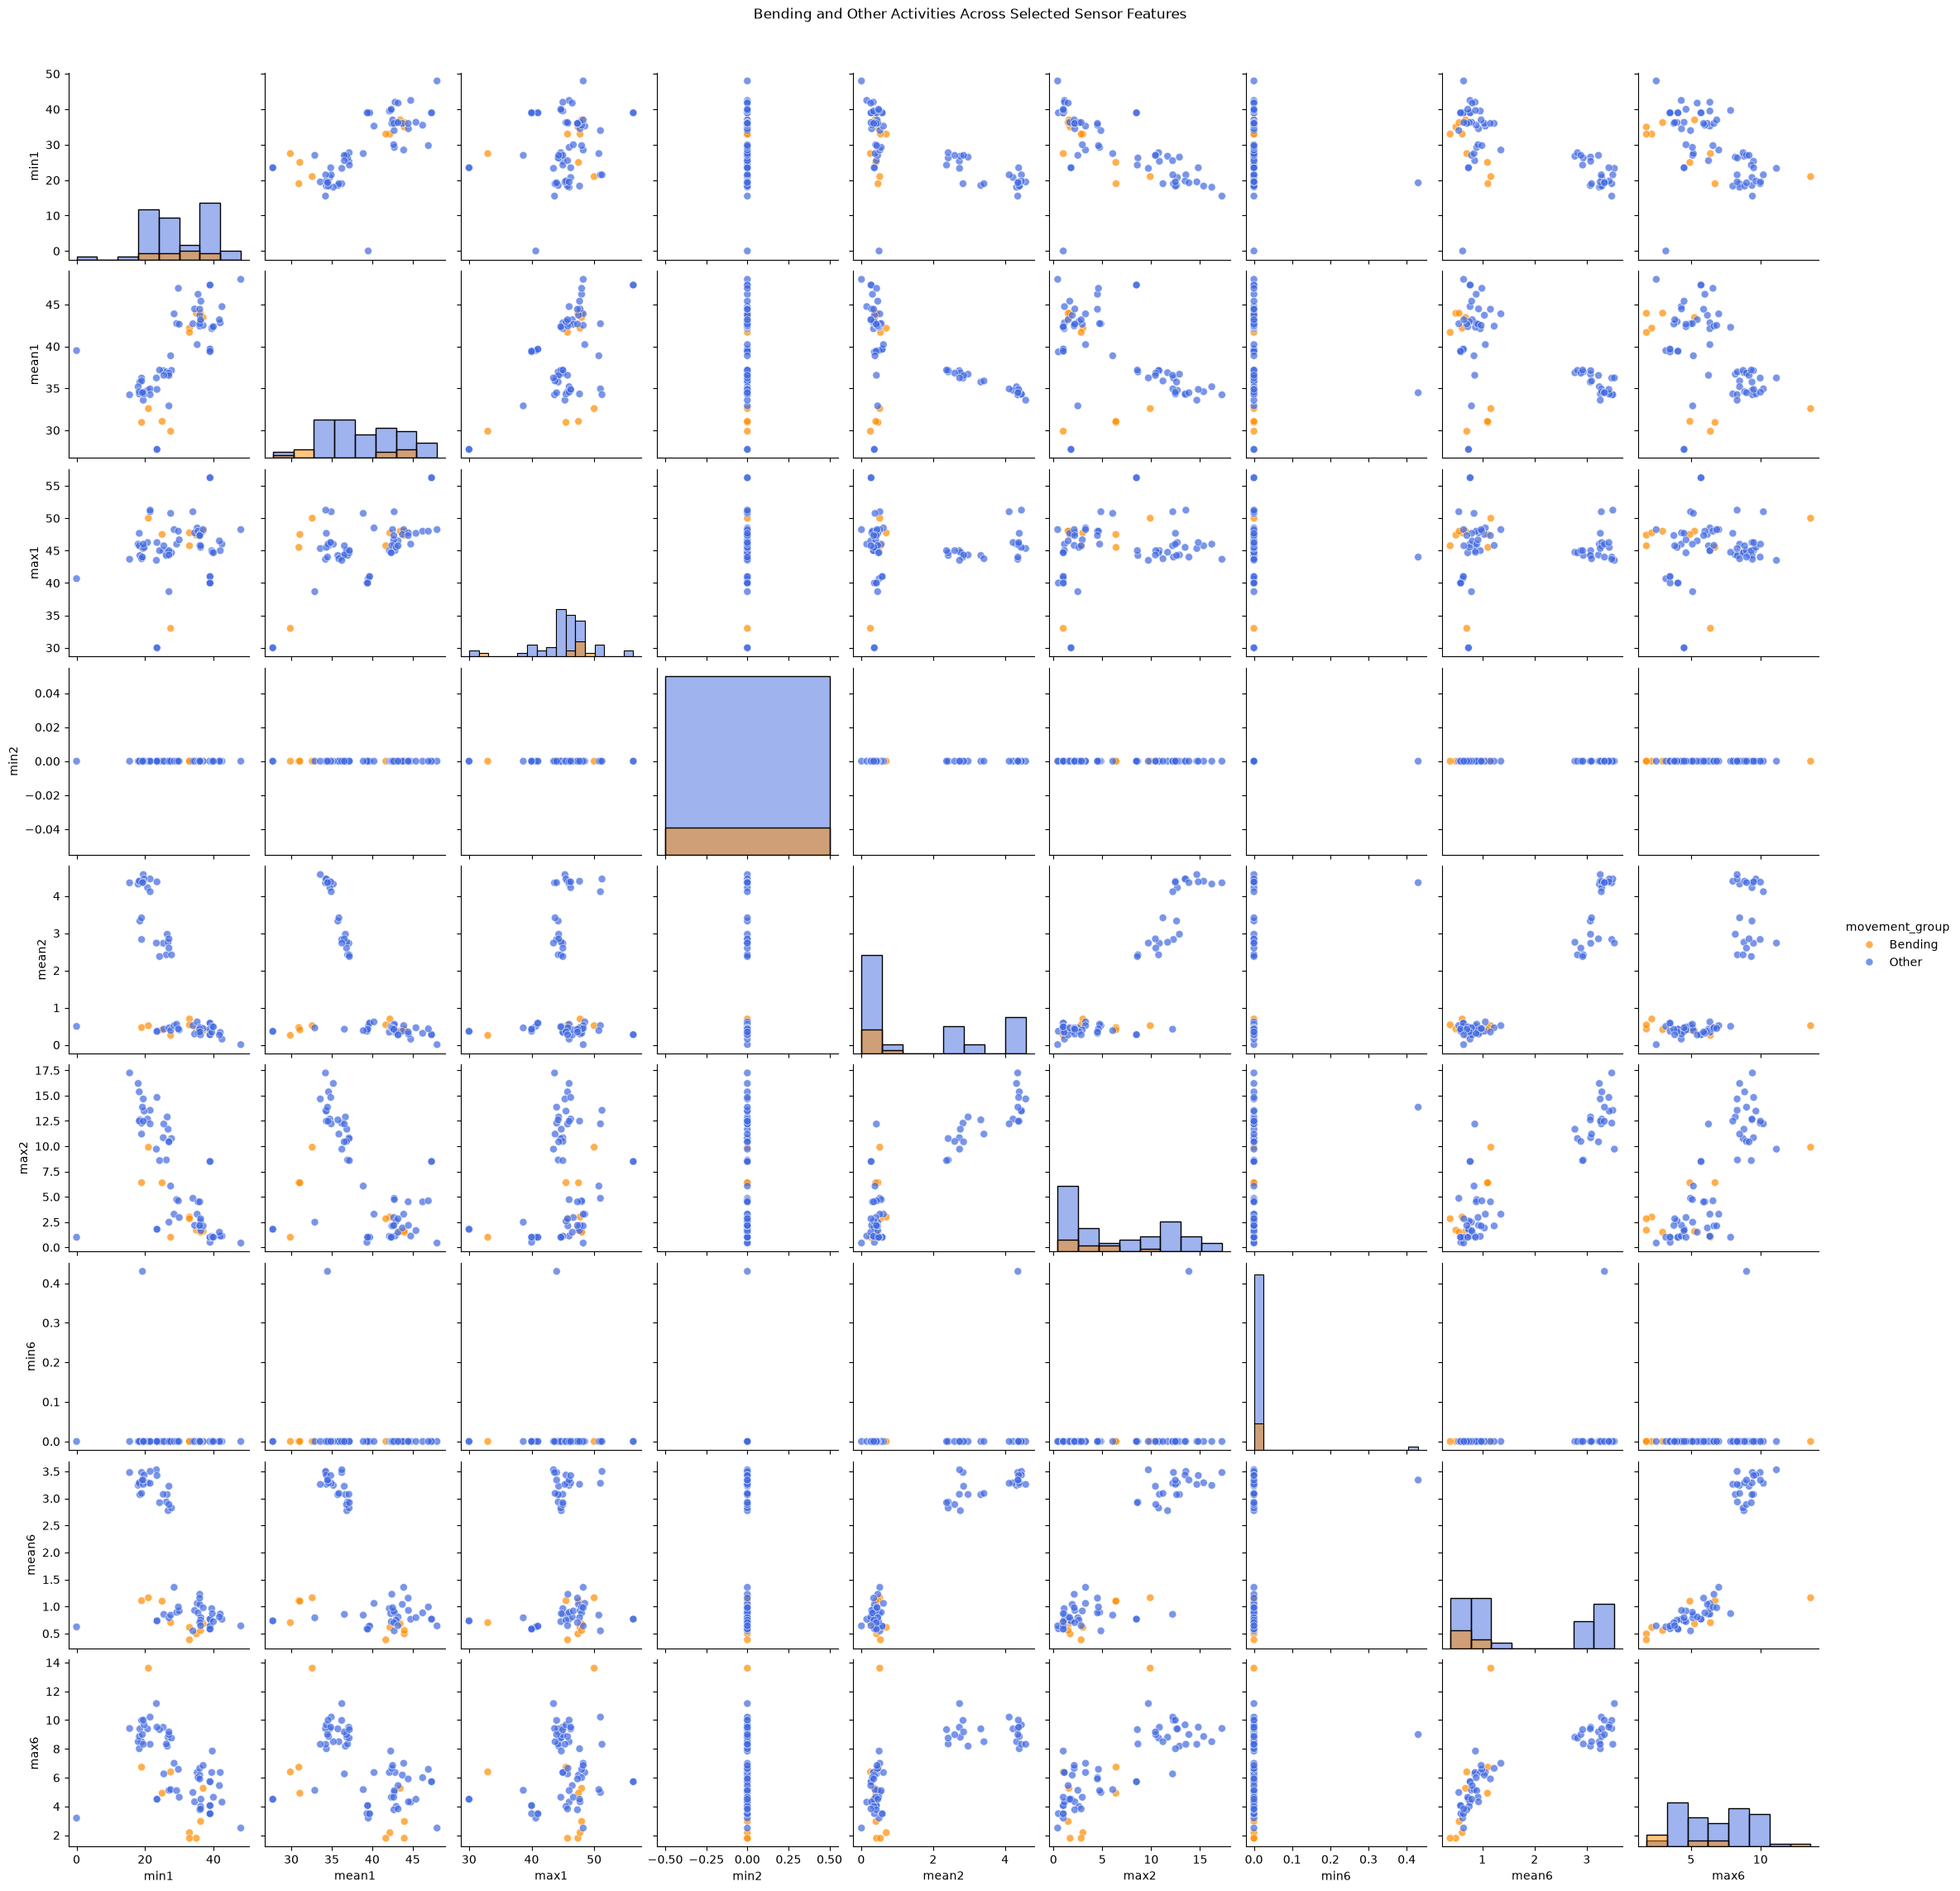

In [16]:
feature_grid = sns.pairplot(
    data=train_panel,
    vars=signal_fields,
    hue="movement_group",
    diag_kind="hist",
    palette={
        "Bending": "darkorange",
        "Other": "royalblue"
    },
    plot_kws={
        "alpha": 0.7,
        "s": 42
    }
)

feature_grid.fig.suptitle(
    "Bending and Other Activities Across Selected Sensor Features",
    y=1.02
)

plt.show()

**Observation:** The two classes overlap for several of the plotted features. The features from time series 2 appear to provide better separation because many bending instances have lower mean and maximum values. However, no single feature separates the classes completely, so a combination of features may give a better classification result.

#### 2(a)(ii) Splitting Each Time Series into Two Parts

Each time series in the training set is divided into two approximately equal parts. The minimum, mean, and maximum are then calculated separately for each part. Scatterplots are created using time series 1, 2, and 6.

In [17]:
def build_segment_profile(frame, pieces):
    profile = {}

    row_groups = np.array_split(
        np.arange(len(frame)),
        pieces
    )

    for part_no, row_group in enumerate(row_groups, start=1):
        frame_part = frame.iloc[row_group]

        for sensor_no, column in enumerate(column_names[1:], start=1):
            readings = frame_part[column]

            profile[f"min{sensor_no}_part{part_no}"] = readings.min()
            profile[f"mean{sensor_no}_part{part_no}"] = readings.mean()
            profile[f"max{sensor_no}_part{part_no}"] = readings.max()

    return profile

In [18]:
two_part_rows = []

training_files = file_check.loc[
    file_check["split"].eq("train")
]

for _, file_info in training_files.iterrows():
    activity_frame = read_file(file_info["file"])
    row_profile = build_segment_profile(activity_frame, pieces=2)

    row_profile["activity"] = file_info["activity"]
    row_profile["movement_group"] = (
        "Bending"
        if file_info["activity"] in {"bending1", "bending2"}
        else "Other"
    )

    two_part_rows.append(row_profile)

two_part_panel = pd.DataFrame(two_part_rows)

print("Training instances:", len(two_part_panel))
print(two_part_panel["movement_group"].value_counts())

Training instances: 69
movement_group
Other      60
Bending     9
Name: count, dtype: int64


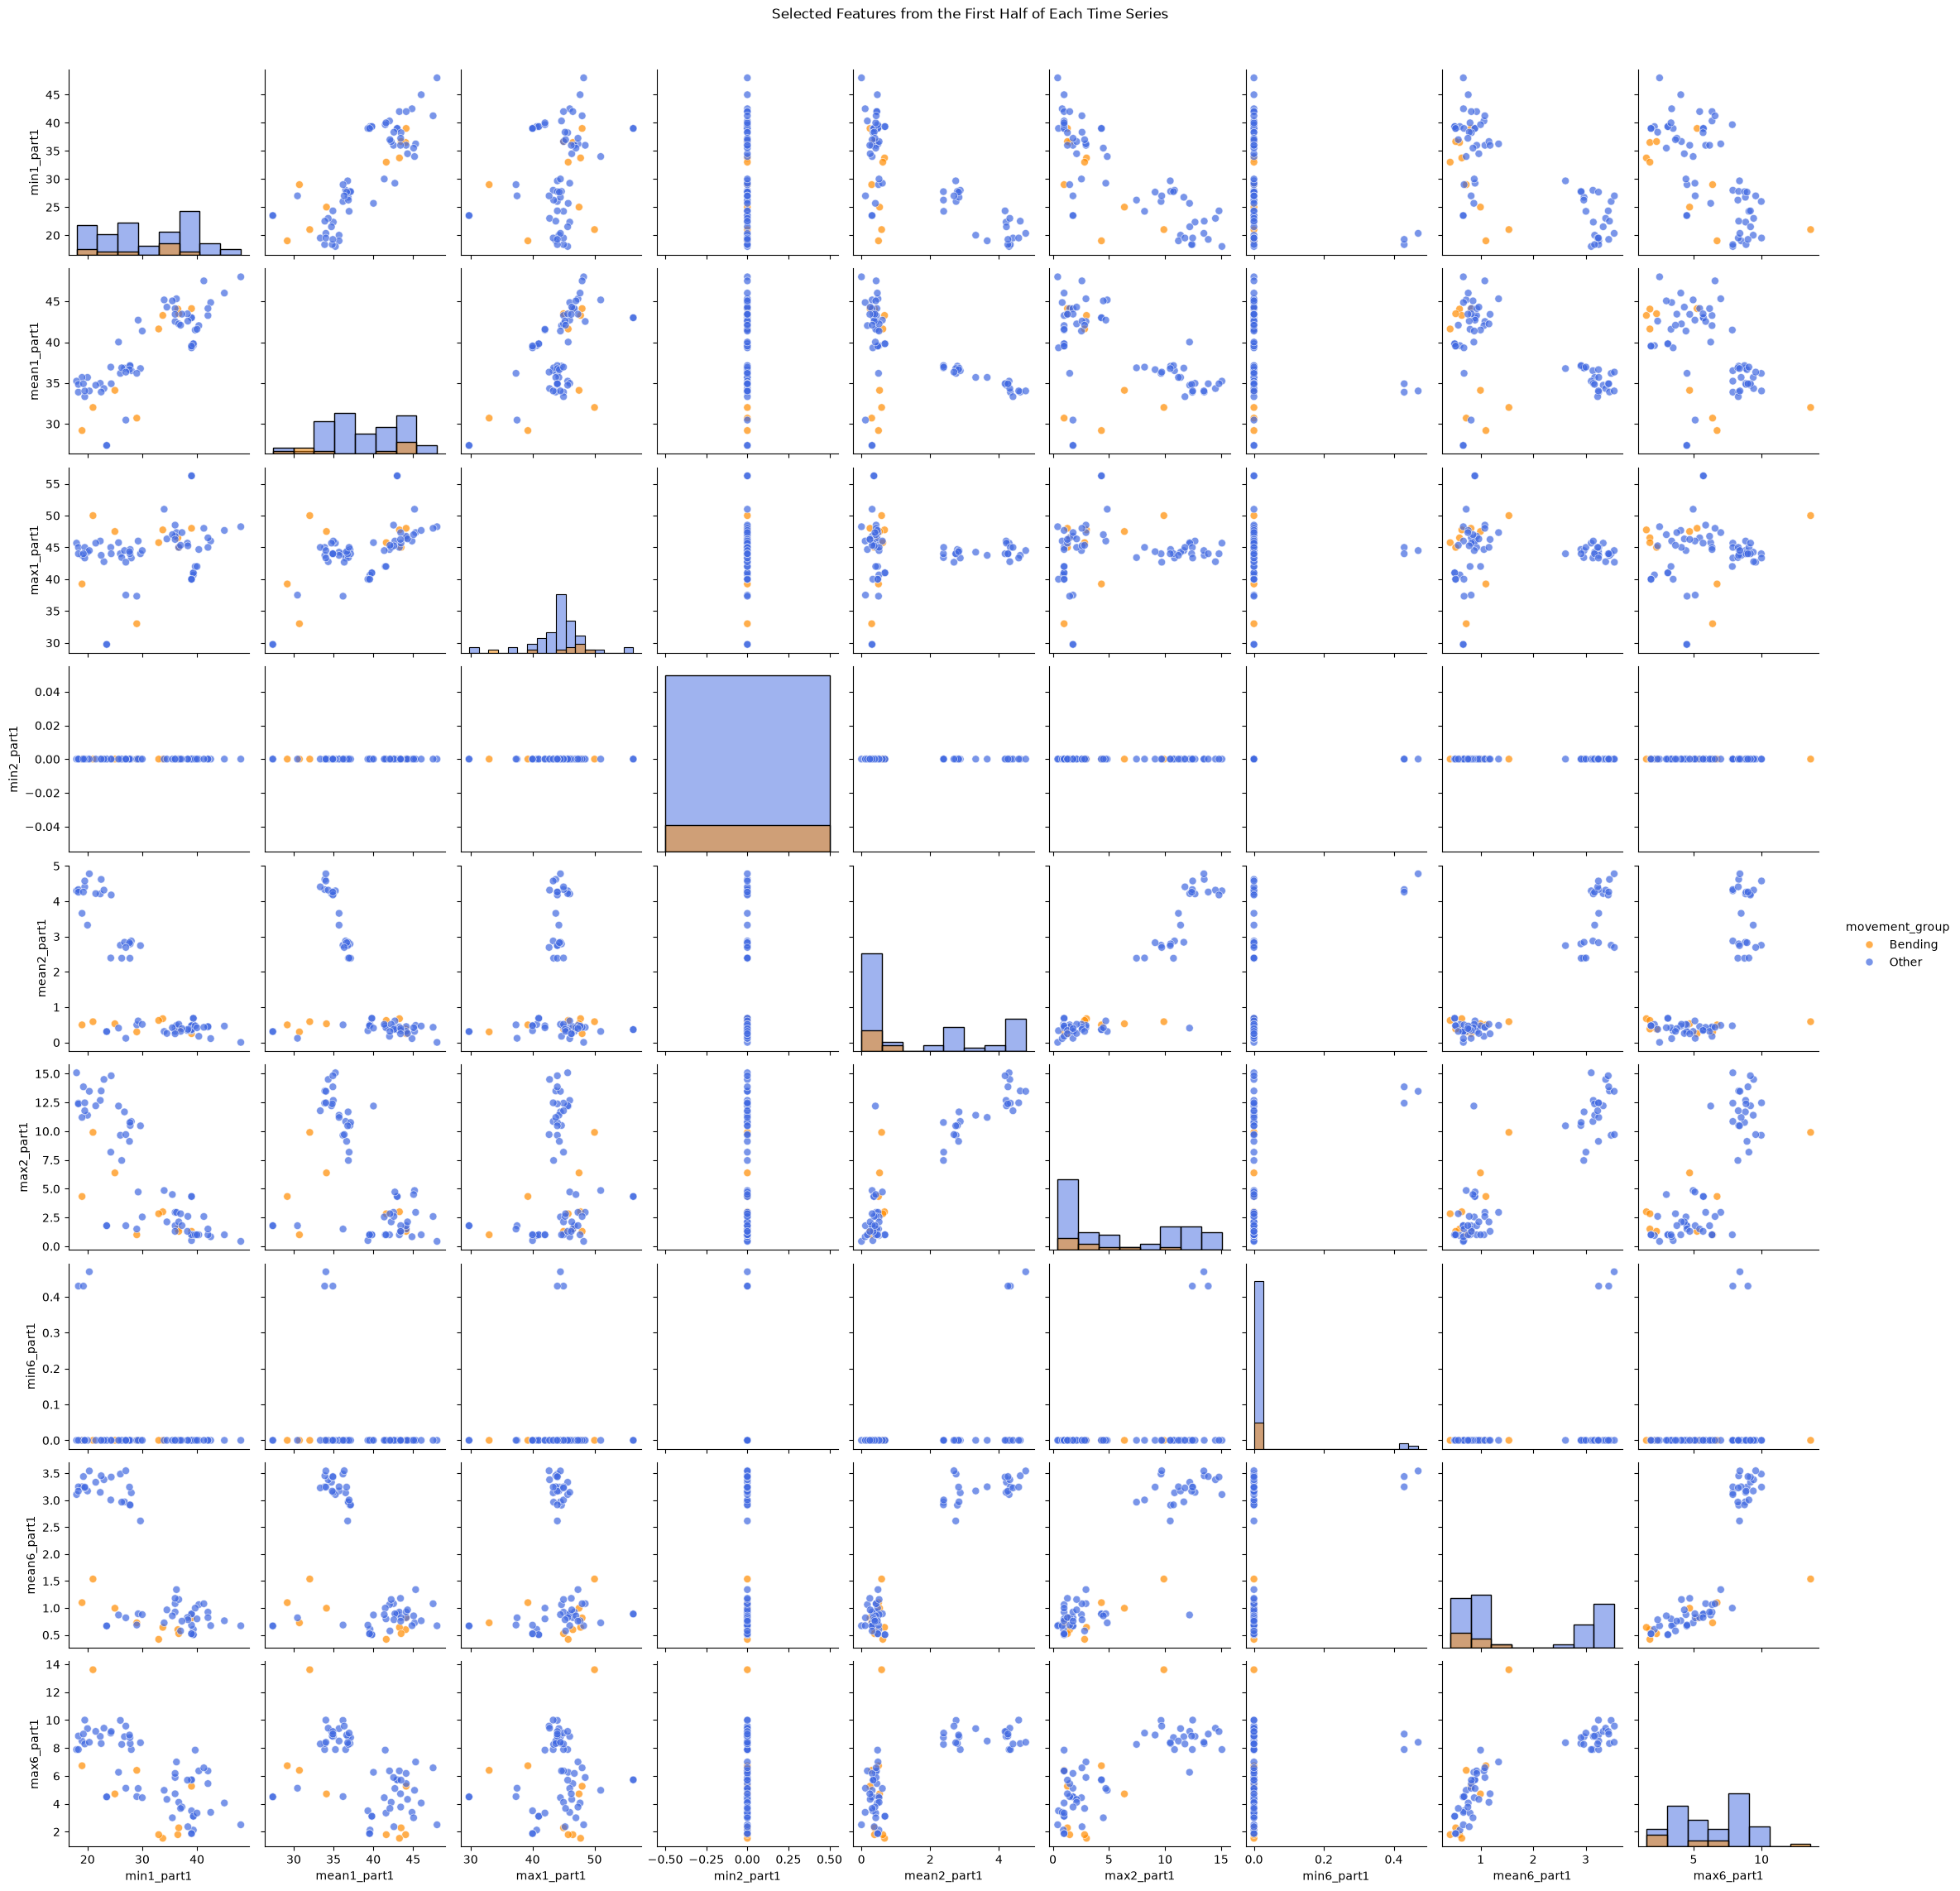

In [19]:
first_half_fields = [
    "min1_part1", "mean1_part1", "max1_part1",
    "min2_part1", "mean2_part1", "max2_part1",
    "min6_part1", "mean6_part1", "max6_part1"
]

first_half_grid = sns.pairplot(
    data=two_part_panel,
    vars=first_half_fields,
    hue="movement_group",
    diag_kind="hist",
    palette={"Bending": "darkorange", "Other": "royalblue"},
    plot_kws={"alpha": 0.7, "s": 42}
)

first_half_grid.fig.suptitle(
    "Selected Features from the First Half of Each Time Series",
    y=1.02
)

plt.show()

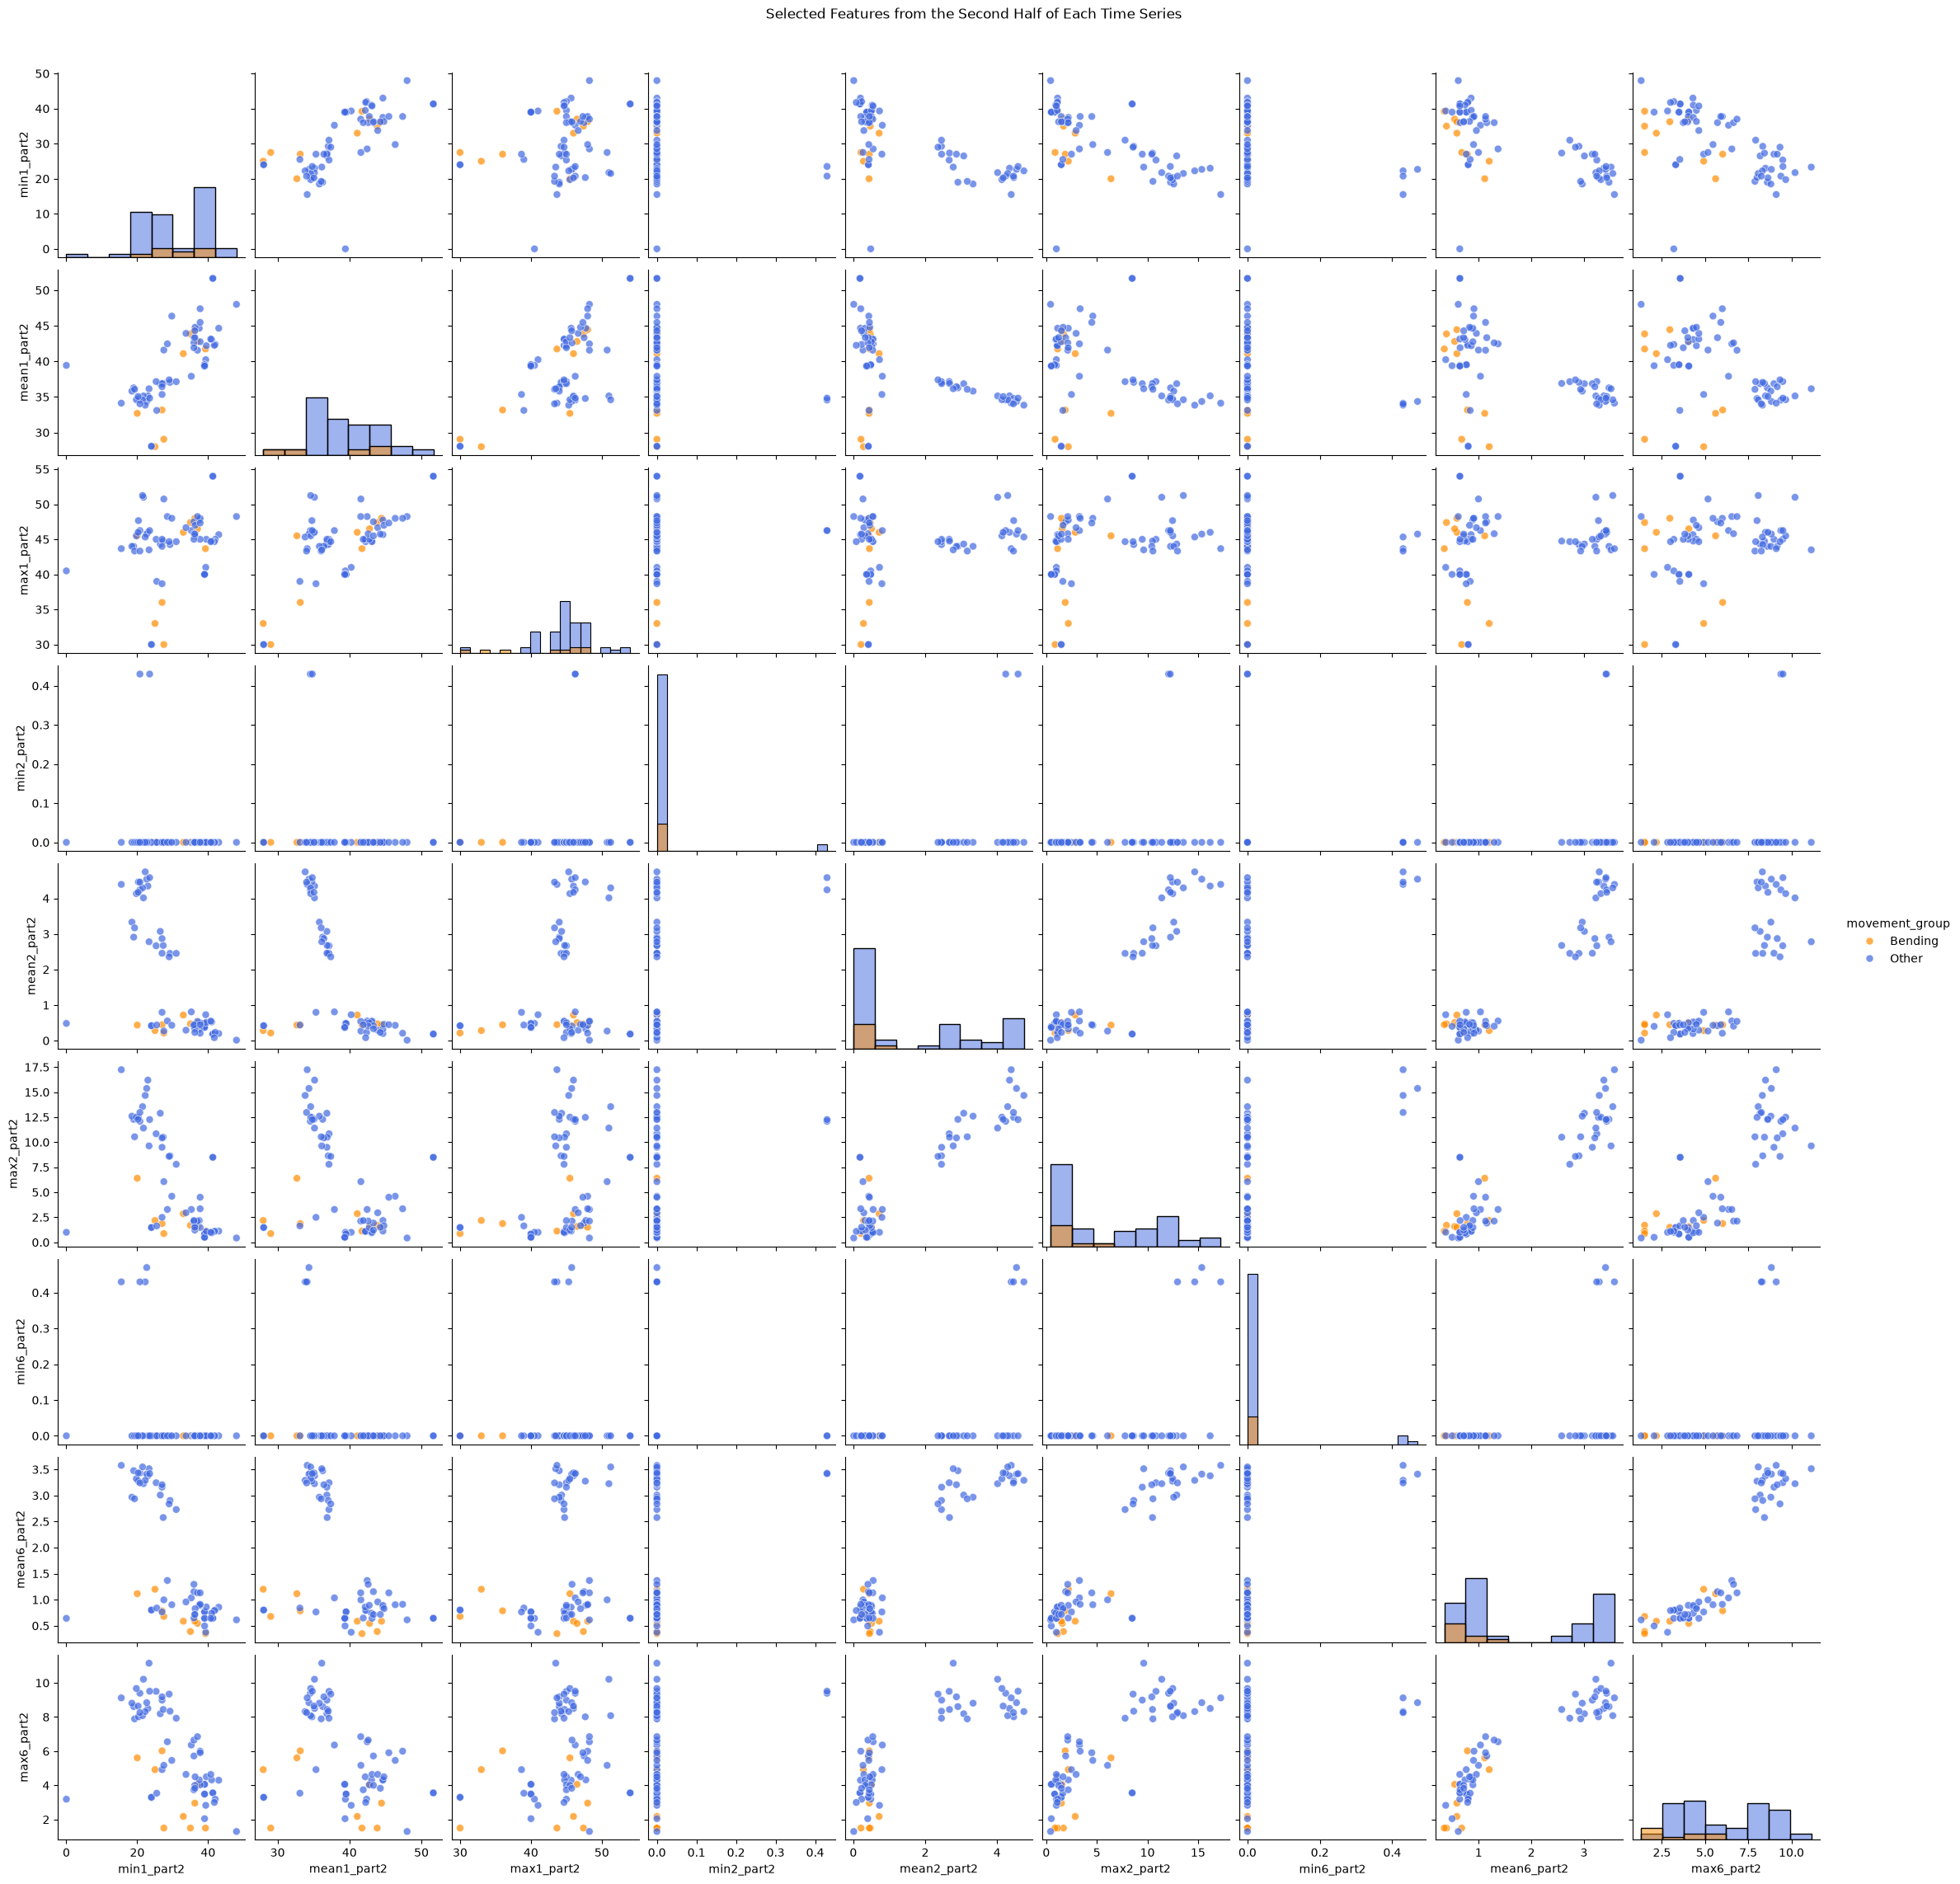

In [20]:
second_half_fields = [
    "min1_part2", "mean1_part2", "max1_part2",
    "min2_part2", "mean2_part2", "max2_part2",
    "min6_part2", "mean6_part2", "max6_part2"
]

second_half_grid = sns.pairplot(
    data=two_part_panel,
    vars=second_half_fields,
    hue="movement_group",
    diag_kind="hist",
    palette={
        "Bending": "darkorange",
        "Other": "royalblue"
    },
    plot_kws={
        "alpha": 0.7,
        "s": 42
    }
)

second_half_grid.fig.suptitle(
    "Selected Features from the Second Half of Each Time Series",
    y=1.02
)

plt.show()

**Comparison:** The plots from the two halves look fairly similar to the plot made from the complete time series. There are a few small changes in where the points appear, but the bending observations still overlap with the other activities in many places. Splitting the time series into two parts gives some extra information, but it does not create a considerable difference in class separation.

#### 2(a)(iii) Logistic Regression with Different Numbers of Segments

Each time series is divided into \(l\) approximately equal segments, where \(l\) ranges from 1 to 20. The minimum, mean, and maximum are extracted from every segment of all six time series. Stratified 5-fold cross-validation is used to choose the best number of segments and the best number of selected features.

In [21]:
def assemble_segment_table(piece_count, split_name):
    assembled_rows = []

    chosen_files = file_check.loc[
        file_check["split"].eq(split_name)
    ]

    for _, file_info in chosen_files.iterrows():
        activity_frame = read_file(file_info["file"])

        row_profile = build_segment_profile(
            activity_frame,
            pieces=piece_count
        )

        row_profile["activity"] = file_info["activity"]
        row_profile["binary_label"] = int(
            file_info["activity"] in {"bending1", "bending2"}
        )

        assembled_rows.append(row_profile)

    return pd.DataFrame(assembled_rows)

In [22]:
for piece_count in [1, 2, 20]:
    segment_table = assemble_segment_table(
        piece_count,
        split_name="train"
    )

    numeric_columns = segment_table.drop(
        columns=["activity", "binary_label"]
    )

    print(
        f"l = {piece_count}: "
        f"{numeric_columns.shape[0]} instances, "
        f"{numeric_columns.shape[1]} features"
    )

l = 1: 69 instances, 18 features
l = 2: 69 instances, 36 features
l = 20: 69 instances, 360 features


To avoid data leakage, feature scaling and feature elimination are performed separately within each cross-validation fold. Selecting features before cross-validation would be incorrect because information from the validation fold could influence the selected feature set.

#### 2(a)(iii) Selecting the Number of Segments and Features

I divided each time series into \(l\) segments, where \(l\) ranges from 1 to 20. For every segment, I extracted the minimum, mean, and maximum from all six time series. I then used stratified 5-fold cross-validation with recursive feature elimination to choose the best combination of \(l\) and the number of features \(p\).

In [23]:
fold_plan = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

search_log = []
saved_selectors = {}

for piece_count in range(1, 21):
    segment_table = assemble_segment_table(
        piece_count,
        split_name="train"
    )

    design_matrix = segment_table.drop(
        columns=["activity", "binary_label"]
    )

    class_vector = segment_table["binary_label"]

    logistic_step = LogisticRegression(
        C=1_000_000,
        solver="liblinear",
        max_iter=5000,
        random_state=42
    )

    model_steps = Pipeline([
        ("scale", StandardScaler()),
        ("model", logistic_step)
    ])

    removal_step = max(
        1,
        design_matrix.shape[1] // 20
    )

    feature_search = RFECV(
        estimator=model_steps,
        step=removal_step,
        cv=fold_plan,
        scoring="accuracy",
        min_features_to_select=1,
        importance_getter="named_steps.model.coef_",
        n_jobs=-1
    )

    feature_search.fit(
        design_matrix,
        class_vector
    )

    best_score = feature_search.cv_results_[
        "mean_test_score"
    ].max()

    search_log.append({
        "segments": piece_count,
        "selected_features": feature_search.n_features_,
        "cv_accuracy": best_score
    })

    saved_selectors[piece_count] = feature_search

    print(
        f"l={piece_count:2d} | "
        f"p={feature_search.n_features_:3d} | "
        f"CV accuracy={best_score:.4f}"
    )

l= 1 | p=  9 | CV accuracy=0.9857
l= 2 | p=  7 | CV accuracy=0.9571
l= 3 | p=  1 | CV accuracy=0.9571
l= 4 | p= 24 | CV accuracy=0.9571
l= 5 | p=  6 | CV accuracy=0.9571
l= 6 | p=  8 | CV accuracy=0.9429
l= 7 | p= 12 | CV accuracy=0.9560
l= 8 | p=  1 | CV accuracy=0.9429
l= 9 | p=  2 | CV accuracy=0.9560
l=10 | p= 81 | CV accuracy=0.9418
l=11 | p=  9 | CV accuracy=0.9286
l=12 | p= 16 | CV accuracy=0.9286
l=13 | p= 91 | CV accuracy=0.9418
l=14 | p=108 | CV accuracy=0.9418
l=15 | p= 75 | CV accuracy=0.9418
l=16 | p=  1 | CV accuracy=0.9571
l=17 | p=  1 | CV accuracy=0.9429
l=18 | p=  1 | CV accuracy=0.9571
l=19 | p= 19 | CV accuracy=0.9714
l=20 | p= 54 | CV accuracy=0.9418


In [24]:
selection_results = pd.DataFrame(search_log)

selection_results

,segments,selected_features,cv_accuracy
0,1,9,0.985714
1,2,7,0.957143
2,3,1,0.957143
3,4,24,0.957143
4,5,6,0.957143
5,6,8,0.942857
6,7,12,0.956044
7,8,1,0.942857
8,9,2,0.956044
9,10,81,0.941758


Feature selection and scaling were performed inside each cross-validation fold. This is important because selecting the features using the full training set before cross-validation would allow information from the validation folds to affect the model. That would make the cross-validation result overly optimistic.

In [25]:
best_row = selection_results.sort_values(
    ["cv_accuracy", "selected_features", "segments"],
    ascending=[False, True, True]
).iloc[0]

best_l = int(best_row["segments"])
best_p = int(best_row["selected_features"])
best_cv_accuracy = best_row["cv_accuracy"]

print("Best number of segments:", best_l)
print("Best number of features:", best_p)
print(f"Best cross-validation accuracy: {best_cv_accuracy:.4f}")

Best number of segments: 1
Best number of features: 9
Best cross-validation accuracy: 0.9857


The best cross-validation result was obtained with \(l=1\) and \(p=9\), with an accuracy of approximately 98.57%. In this case, splitting each time series into smaller segments did not improve the result. The features calculated from the original, unsplit time series produced the highest cross-validation accuracy.

#### 2(a)(iv) Training Performance

Using the values selected through cross-validation, a final logistic regression model is fitted to the training data. The model is evaluated using its confusion matrix, ROC curve, AUC, coefficients, and p-values.

In [26]:
best_train_table = assemble_segment_table(
    best_l,
    split_name="train"
)

full_design = best_train_table.drop(
    columns=["activity", "binary_label"]
)

train_labels = best_train_table["binary_label"]

winning_selector = saved_selectors[best_l]

kept_fields = full_design.columns[
    winning_selector.support_
].tolist()

print("Number of selected features:", len(kept_fields))
print()

for field in kept_fields:
    print(field)

Number of selected features: 9

min1_part1
max2_part1
min3_part1
mean3_part1
mean4_part1
max4_part1
min5_part1
mean5_part1
max5_part1


The recursive feature elimination procedure selected nine features for the final model. These features include measurements from multiple time series, indicating that information from more than one sensor is useful for distinguishing bending activities from the other activities.

In [27]:
reduced_design = full_design[kept_fields]

final_binary_model = Pipeline([
    ("scale", StandardScaler()),
    (
        "model",
        LogisticRegression(
            C=1_000_000,
            solver="liblinear",
            max_iter=5000,
            random_state=42
        )
    )
])

final_binary_model.fit(
    reduced_design,
    train_labels
)

train_predictions = final_binary_model.predict(
    reduced_design
)

train_probabilities = final_binary_model.predict_proba(
    reduced_design
)[:, 1]

training_accuracy = accuracy_score(
    train_labels,
    train_predictions
)

training_auc = roc_auc_score(
    train_labels,
    train_probabilities
)

print(f"Training accuracy: {training_accuracy:.4f}")
print(f"Training AUC: {training_auc:.4f}")

Training accuracy: 1.0000
Training AUC: 1.0000


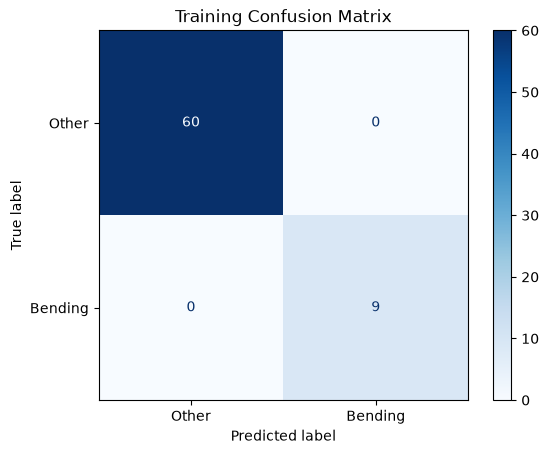

In [28]:
training_matrix = confusion_matrix(
    train_labels,
    train_predictions
)

matrix_display = ConfusionMatrixDisplay(
    confusion_matrix=training_matrix,
    display_labels=["Other", "Bending"]
)

matrix_display.plot(cmap="Blues")
plt.title("Training Confusion Matrix")
plt.show()

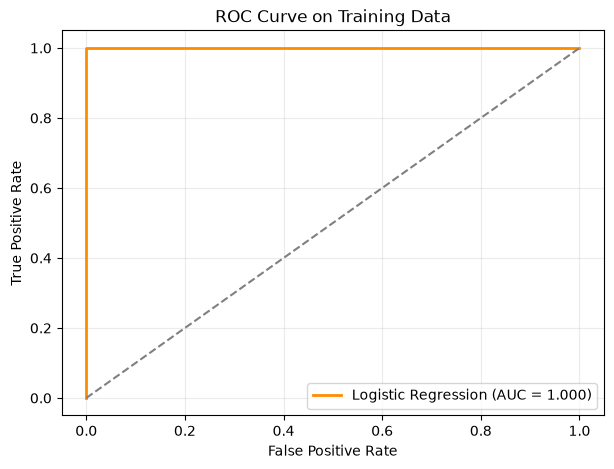

In [29]:
false_positive_rate, true_positive_rate, _ = roc_curve(
    train_labels,
    train_probabilities
)

plt.figure(figsize=(7, 5))

plt.plot(
    false_positive_rate,
    true_positive_rate,
    color="darkorange",
    linewidth=2,
    label=f"Logistic Regression (AUC = {training_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve on Training Data")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

The model correctly classified all of the training instances, resulting in a training accuracy and AUC of 1.00. This indicates excellent performance on the training data. However, perfect training performance may also be a sign of complete or nearly complete separation, so the test-set results are needed to evaluate how well the model generalizes.

In [30]:
fitted_logistic = final_binary_model.named_steps["model"]

coefficient_table = pd.DataFrame({
    "Feature": kept_fields,
    "Coefficient": fitted_logistic.coef_[0]
})

intercept_row = pd.DataFrame({
    "Feature": ["Intercept"],
    "Coefficient": [fitted_logistic.intercept_[0]]
})

coefficient_table = pd.concat(
    [intercept_row, coefficient_table],
    ignore_index=True
)

coefficient_table.round(4)

,Feature,Coefficient
0,Intercept,-15.8825
1,min1_part1,-4.4532
2,max2_part1,-4.5051
3,min3_part1,-3.2218
4,mean3_part1,-4.4769
5,mean4_part1,-1.9252
6,max4_part1,2.9926
7,min5_part1,8.6689
8,mean5_part1,1.5381
9,max5_part1,10.7422


The sign of each coefficient shows how the corresponding feature affects the predicted probability of bending. A positive coefficient increases the predicted probability of bending, while a negative coefficient decreases it.

In [31]:
print(
    "Reliable p-values cannot be reported because "
    "the training data exhibits complete separation."
)

Reliable p-values cannot be reported because the training data exhibits complete separation.


The training data exhibits complete separation because the logistic regression model classifies every training instance correctly. As a result, the maximum-likelihood coefficient estimates continue to increase in magnitude, and reliable p-values cannot be obtained. Therefore, the coefficient signs can be examined, but their numerical values and p-values should not be interpreted as stable estimates.

#### 2(a)(v) Test Performance

The final logistic regression model is now evaluated on the test set. The same nine features selected from the training data are used to calculate the test predictions. The test confusion matrix, ROC curve, AUC, and accuracy are reported below.

In [32]:
best_test_table = assemble_segment_table(
    best_l,
    split_name="test"
)

test_design = best_test_table[kept_fields]
test_labels = best_test_table["binary_label"]

test_predictions = final_binary_model.predict(
    test_design
)

test_probabilities = final_binary_model.predict_proba(
    test_design
)[:, 1]

test_accuracy = accuracy_score(
    test_labels,
    test_predictions
)

test_auc = roc_auc_score(
    test_labels,
    test_probabilities
)

print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test AUC: {test_auc:.4f}")
print(f"Cross-validation accuracy: {best_cv_accuracy:.4f}")

Test accuracy: 0.9474
Test AUC: 1.0000
Cross-validation accuracy: 0.9857


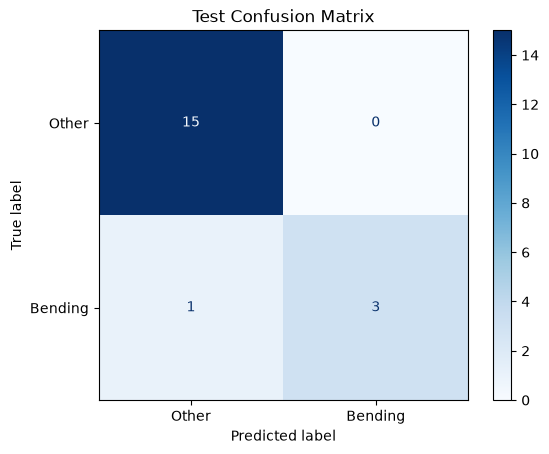

In [33]:
test_matrix = confusion_matrix(
    test_labels,
    test_predictions
)

test_matrix_display = ConfusionMatrixDisplay(
    confusion_matrix=test_matrix,
    display_labels=["Other", "Bending"]
)

test_matrix_display.plot(cmap="Blues")
plt.title("Test Confusion Matrix")
plt.show()

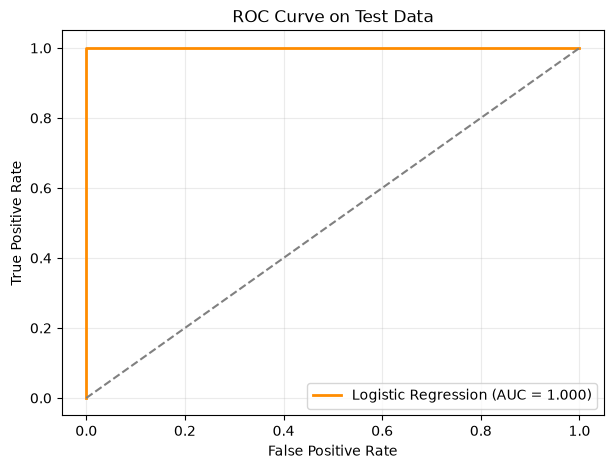

In [34]:
test_fpr, test_tpr, _ = roc_curve(
    test_labels,
    test_probabilities
)

plt.figure(figsize=(7, 5))

plt.plot(
    test_fpr,
    test_tpr,
    color="darkorange",
    linewidth=2,
    label=f"Logistic Regression (AUC = {test_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve on Test Data")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

The model achieved a test accuracy of 94.74%, which is slightly lower than the cross-validation accuracy of 98.57%. This small decrease is reasonable because the test set contains observations that were not used while selecting or fitting the model. The test AUC is 1.00, indicating that the model ranks the bending instances above the other instances correctly, even though one observation is misclassified at the default probability threshold of 0.5.

#### 2(a)(vi) Separation in Logistic Regression

The training accuracy and training AUC are both 1.00, and the unregularized logistic regression produces a perfect-separation warning. Therefore, complete separation exists in the training data. Under complete separation, the maximum-likelihood coefficient estimates do not remain finite, so the coefficients and their p-values cannot be estimated reliably. Regularization can reduce this problem by placing a penalty on very large coefficient values.

#### 2(a)(vii) Case-Control Sampling

The training data contains considerably fewer bending instances than other activity instances. To reduce this imbalance, the bending observations are sampled with replacement until both classes have the same number of instances. A logistic regression model is then fitted to the balanced sample.

Because case-control sampling changes the proportion of bending observations, the intercept is adjusted using the difference between the class odds in the original and sampled training data. The slope coefficients do not require this correction.

In [35]:
case_rows = reduced_design.loc[
    train_labels.eq(1)
].copy()

control_rows = reduced_design.loc[
    train_labels.eq(0)
].copy()

sampled_cases = case_rows.sample(
    n=len(control_rows),
    replace=True,
    random_state=42
)

balanced_design = pd.concat(
    [control_rows, sampled_cases],
    axis=0
)

balanced_labels = pd.Series(
    [0] * len(control_rows) + [1] * len(sampled_cases),
    index=balanced_design.index,
    name="binary_label"
)

shuffle_order = np.random.default_rng(42).permutation(
    len(balanced_design)
)

balanced_design = balanced_design.iloc[shuffle_order]
balanced_labels = balanced_labels.iloc[shuffle_order]

print("Original class counts:")
print(train_labels.value_counts().sort_index())

print("\nBalanced class counts:")
print(balanced_labels.value_counts().sort_index())

Original class counts:
binary_label
0    60
1     9
Name: count, dtype: int64

Balanced class counts:
binary_label
0    60
1    60
Name: count, dtype: int64


In [36]:
case_control_model = Pipeline([
    ("scale", StandardScaler()),
    (
        "model",
        LogisticRegression(
            C=1_000_000,
            solver="liblinear",
            max_iter=5000,
            random_state=42
        )
    )
])

case_control_model.fit(
    balanced_design,
    balanced_labels
)

original_rate = train_labels.mean()
sampled_rate = balanced_labels.mean()

intercept_correction = (
    np.log(original_rate / (1 - original_rate))
    - np.log(sampled_rate / (1 - sampled_rate))
)

case_control_model.named_steps["model"].intercept_[0] += (
    intercept_correction
)

print(f"Original bending proportion: {original_rate:.4f}")
print(f"Sampled bending proportion: {sampled_rate:.4f}")
print(f"Intercept correction: {intercept_correction:.4f}")

Original bending proportion: 0.1304
Sampled bending proportion: 0.5000
Intercept correction: -1.8971


In [37]:
adjusted_predictions = case_control_model.predict(
    test_design
)

adjusted_probabilities = case_control_model.predict_proba(
    test_design
)[:, 1]

adjusted_accuracy = accuracy_score(
    test_labels,
    adjusted_predictions
)

adjusted_auc = roc_auc_score(
    test_labels,
    adjusted_probabilities
)

print(f"Case-control test accuracy: {adjusted_accuracy:.4f}")
print(f"Case-control test AUC: {adjusted_auc:.4f}")

Case-control test accuracy: 0.9474
Case-control test AUC: 1.0000


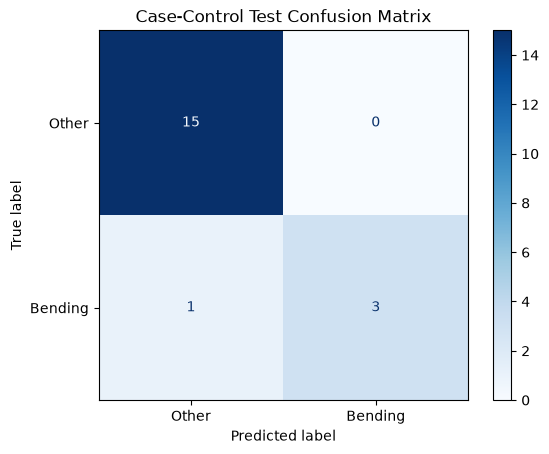

In [38]:
adjusted_matrix = confusion_matrix(
    test_labels,
    adjusted_predictions
)

adjusted_matrix_display = ConfusionMatrixDisplay(
    confusion_matrix=adjusted_matrix,
    display_labels=["Other", "Bending"]
)

adjusted_matrix_display.plot(cmap="Blues")
plt.title("Case-Control Test Confusion Matrix")
plt.show()

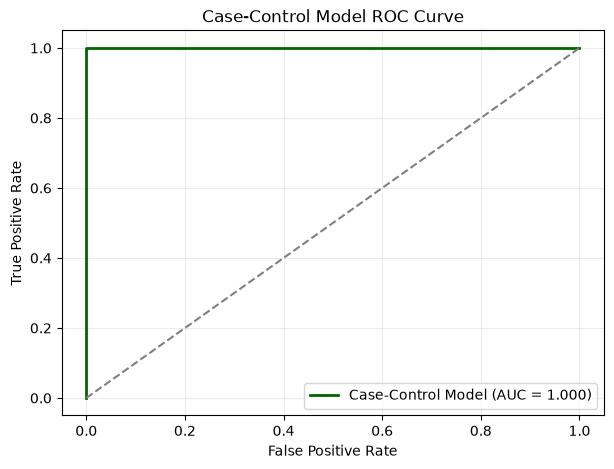

In [39]:
adjusted_fpr, adjusted_tpr, _ = roc_curve(
    test_labels,
    adjusted_probabilities
)

plt.figure(figsize=(7, 5))

plt.plot(
    adjusted_fpr,
    adjusted_tpr,
    color="darkgreen",
    linewidth=2,
    label=f"Case-Control Model (AUC = {adjusted_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Case-Control Model ROC Curve")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

The original training set was imbalanced, with bending observations making up only 13.04% of the data. After case-control sampling, both classes represented 50% of the sampled training set. Since this changed the class proportions, the model intercept was adjusted by -1.8971.

The adjusted case-control model achieved a test accuracy of 94.74% and an AUC of 1.00. These results are the same as those of the original logistic regression model. Therefore, balancing the classes did not change the final test performance in this case.

### 2(b) Binary Classification Using L1-Penalized Logistic Regression

#### 2(b)(i) Selection of the Number of Segments and Regularization Strength

An L1-penalized logistic regression model is used for binary classification. Cross-validation is performed for both the number of segments \(l\) and the regularization parameter \(C\). Feature standardization is performed separately inside each cross-validation fold to avoid data leakage.

In [40]:
from sklearn.model_selection import GridSearchCV

candidates_c = np.logspace(-4, 4, 20)

l1_search_rows = []
l1_search_models = {}

for segment_count in range(1, 21):
    segmented_train = assemble_segment_table(
        segment_count,
        split_name="train"
    )

    segment_features = segmented_train.drop(
        columns=["activity", "binary_label"]
    )

    segment_labels = segmented_train["binary_label"]

    l1_pipeline = Pipeline([
        ("scale", StandardScaler()),
        (
            "classifier",
            LogisticRegression(
                l1_ratio=1.0,
                solver="liblinear",
                max_iter=5000,
                random_state=42
)
        )
    ])

    parameter_grid = {
        "classifier__C": candidates_c
    }

    l1_grid = GridSearchCV(
        estimator=l1_pipeline,
        param_grid=parameter_grid,
        scoring="accuracy",
        cv=fold_plan,
        n_jobs=-1
    )

    l1_grid.fit(
        segment_features,
        segment_labels
    )

    l1_search_rows.append({
        "segments": segment_count,
        "best_C": l1_grid.best_params_["classifier__C"],
        "cv_accuracy": l1_grid.best_score_
    })

    l1_search_models[segment_count] = l1_grid.best_estimator_

    print(
        f"Segments: {segment_count:2d} | "
        f"Best C: {l1_grid.best_params_['classifier__C']:.6f} | "
        f"CV accuracy: {l1_grid.best_score_:.4f}"
    )

Segments:  1 | Best C: 0.615848 | CV accuracy: 0.9714
Segments:  2 | Best C: 0.615848 | CV accuracy: 0.9571
Segments:  3 | Best C: 0.233572 | CV accuracy: 0.9714
Segments:  4 | Best C: 0.615848 | CV accuracy: 0.9714
Segments:  5 | Best C: 0.615848 | CV accuracy: 0.9429
Segments:  6 | Best C: 1.623777 | CV accuracy: 0.9571
Segments:  7 | Best C: 78.475997 | CV accuracy: 0.9571
Segments:  8 | Best C: 10000.000000 | CV accuracy: 0.9286
Segments:  9 | Best C: 0.615848 | CV accuracy: 0.9418
Segments: 10 | Best C: 78.475997 | CV accuracy: 0.9429
Segments: 11 | Best C: 1.623777 | CV accuracy: 0.9571
Segments: 12 | Best C: 0.615848 | CV accuracy: 0.9857
Segments: 13 | Best C: 0.233572 | CV accuracy: 0.9714
Segments: 14 | Best C: 1.623777 | CV accuracy: 0.9571
Segments: 15 | Best C: 1.623777 | CV accuracy: 0.9429
Segments: 16 | Best C: 0.615848 | CV accuracy: 0.9571
Segments: 17 | Best C: 0.615848 | CV accuracy: 0.9571
Segments: 18 | Best C: 0.615848 | CV accuracy: 0.9714
Segments: 19 | Best C:

In [41]:
l1_search_table = pd.DataFrame(
    l1_search_rows
)

l1_search_table

,segments,best_C,cv_accuracy
0,1,0.615848,0.971429
1,2,0.615848,0.957143
2,3,0.233572,0.971429
3,4,0.615848,0.971429
4,5,0.615848,0.942857
5,6,1.623777,0.957143
6,7,78.475997,0.957143
7,8,10000.000000,0.928571
8,9,0.615848,0.941758
9,10,78.475997,0.942857


In [42]:
best_l1_row = l1_search_table.sort_values(
    ["cv_accuracy", "segments", "best_C"],
    ascending=[False, True, True]
).iloc[0]

best_l1_segments = int(
    best_l1_row["segments"]
)

best_l1_c = float(
    best_l1_row["best_C"]
)

best_l1_cv = float(
    best_l1_row["cv_accuracy"]
)

best_l1_model = l1_search_models[
    best_l1_segments
]

print("Best number of segments:", best_l1_segments)
print(f"Best C: {best_l1_c:.6f}")
print(f"Best cross-validation accuracy: {best_l1_cv:.4f}")

Best number of segments: 12
Best C: 0.615848
Best cross-validation accuracy: 0.9857


The best L1-penalized logistic regression model was obtained with \(l=12\) segments and \(C=0.615848\). Its cross-validation accuracy was approximately 98.57%. The selected model is now evaluated on the test set.

In [43]:
l1_test_table = assemble_segment_table(
    best_l1_segments,
    split_name="test"
)

l1_test_design = l1_test_table.drop(
    columns=["activity", "binary_label"]
)

l1_test_labels = l1_test_table["binary_label"]

l1_test_predictions = best_l1_model.predict(
    l1_test_design
)

l1_test_probabilities = best_l1_model.predict_proba(
    l1_test_design
)[:, 1]

l1_test_accuracy = accuracy_score(
    l1_test_labels,
    l1_test_predictions
)

l1_test_auc = roc_auc_score(
    l1_test_labels,
    l1_test_probabilities
)

print(f"L1 test accuracy: {l1_test_accuracy:.4f}")
print(f"L1 test AUC: {l1_test_auc:.4f}")

L1 test accuracy: 0.9474
L1 test AUC: 0.9833


In [44]:
l1_coefficients = best_l1_model.named_steps[
    "classifier"
].coef_[0]

l1_feature_names = l1_test_design.columns

nonzero_mask = ~np.isclose(
    l1_coefficients,
    0
)

selected_l1_features = l1_feature_names[
    nonzero_mask
].tolist()

print(
    "Number of nonzero features:",
    len(selected_l1_features)
)

for feature in selected_l1_features:
    print(feature)

Number of nonzero features: 5
mean5_part2
max1_part7
mean4_part9
min5_part11
max6_part11


The final L1 model kept five features with nonzero coefficients. These features come from different segments and sensor measurements. Compared with the earlier feature-selection method, L1 regularization produced a smaller model by automatically setting the remaining coefficients to zero.

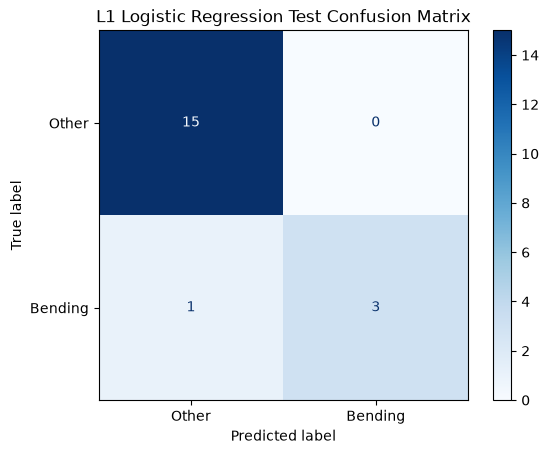

In [45]:
l1_test_matrix = confusion_matrix(
    l1_test_labels,
    l1_test_predictions
)

l1_matrix_plot = ConfusionMatrixDisplay(
    confusion_matrix=l1_test_matrix,
    display_labels=["Other", "Bending"]
)

l1_matrix_plot.plot(cmap="Blues")
plt.title("L1 Logistic Regression Test Confusion Matrix")
plt.show()

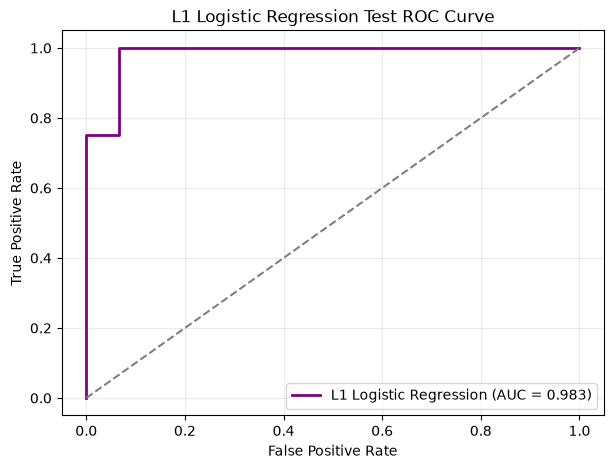

In [46]:
l1_false_positive, l1_true_positive, _ = roc_curve(
    l1_test_labels,
    l1_test_probabilities
)

plt.figure(figsize=(7, 5))

plt.plot(
    l1_false_positive,
    l1_true_positive,
    color="purple",
    linewidth=2,
    label=f"L1 Logistic Regression (AUC = {l1_test_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("L1 Logistic Regression Test ROC Curve")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

The L1-penalized model achieved a test accuracy of 94.74% and a test AUC of 0.9833. Its test accuracy is slightly lower than its cross-validation accuracy of 98.57%, but it still performs well on the unseen test data.

#### 2(b)(ii) Comparison with Feature Selection

Both methods achieved the same test accuracy of 94.74%. The earlier logistic regression model had an AUC of 1.00, while the L1-penalized model had an AUC of 0.9833. Therefore, the earlier model performed slightly better based on AUC, although their classification accuracies were the same.

The L1 model retained only five features, while recursive feature elimination selected nine. L1 regularization was easier to implement because it performed feature selection while fitting the model. The recursive feature elimination approach required a separate search over the number of selected features.

### 2(c) Multiclass Classification

#### 2(c)(i) L1-Penalized Multinomial Logistic Regression

The binary labels are replaced with the original seven activity labels. Cross-validation is used to select the number of segments and the regularization parameter for an L1-penalized multiclass logistic regression model.

In [47]:
multi_fold_plan = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

multi_c_values = np.logspace(-3, 3, 12)

multi_search_rows = []
multi_search_models = {}

In [48]:
for segment_count in range(1, 21):
    activity_train = assemble_segment_table(
        segment_count,
        split_name="train"
    )

    activity_features = activity_train.drop(
        columns=["activity", "binary_label"]
    )

    activity_labels = activity_train["activity"]

    multi_pipeline = Pipeline([
        ("scale", StandardScaler()),
        (
            "classifier",
            LogisticRegression(
                l1_ratio=1.0,
                solver="saga",
                max_iter=10000,
                random_state=42
            )
        )
    ])

    multi_grid = GridSearchCV(
        estimator=multi_pipeline,
        param_grid={
            "classifier__C": multi_c_values
        },
        scoring="accuracy",
        cv=multi_fold_plan,
        n_jobs=-1
    )

    multi_grid.fit(
        activity_features,
        activity_labels
    )

    multi_search_rows.append({
        "segments": segment_count,
        "best_C": multi_grid.best_params_[
            "classifier__C"
        ],
        "cv_accuracy": multi_grid.best_score_
    })

    multi_search_models[segment_count] = (
        multi_grid.best_estimator_
    )

    print(
        f"Segments: {segment_count:2d} | "
        f"Best C: "
        f"{multi_grid.best_params_['classifier__C']:.6f} | "
        f"CV accuracy: {multi_grid.best_score_:.4f}"
    )

Segments:  1 | Best C: 1.873817 | CV accuracy: 0.8693
Segments:  2 | Best C: 284.803587 | CV accuracy: 0.8391
Segments:  3 | Best C: 1000.000000 | CV accuracy: 0.8252
Segments:  4 | Best C: 23.101297 | CV accuracy: 0.7949
Segments:  5 | Best C: 284.803587 | CV accuracy: 0.8399
Segments:  6 | Best C: 81.113083 | CV accuracy: 0.8399
Segments:  7 | Best C: 23.101297 | CV accuracy: 0.7361
Segments:  8 | Best C: 0.533670 | CV accuracy: 0.7525
Segments:  9 | Best C: 1000.000000 | CV accuracy: 0.8268
Segments: 10 | Best C: 81.113083 | CV accuracy: 0.8113
Segments: 11 | Best C: 1000.000000 | CV accuracy: 0.7533
Segments: 12 | Best C: 1000.000000 | CV accuracy: 0.8105
Segments: 13 | Best C: 284.803587 | CV accuracy: 0.8260
Segments: 14 | Best C: 81.113083 | CV accuracy: 0.8113
Segments: 15 | Best C: 1000.000000 | CV accuracy: 0.8113
Segments: 16 | Best C: 1000.000000 | CV accuracy: 0.7827
Segments: 17 | Best C: 0.533670 | CV accuracy: 0.8096
Segments: 18 | Best C: 1000.000000 | CV accuracy: 0.7

In [49]:
multi_search_table = pd.DataFrame(
    multi_search_rows
)

multi_search_table

,segments,best_C,cv_accuracy
0,1,1.873817,0.869281
1,2,284.803587,0.839052
2,3,1000.000000,0.825163
3,4,23.101297,0.794935
4,5,284.803587,0.839869
5,6,81.113083,0.839869
6,7,23.101297,0.736111
7,8,0.533670,0.752451
8,9,1000.000000,0.826797
9,10,81.113083,0.811275


In [50]:
best_multi_row = multi_search_table.sort_values(
    ["cv_accuracy", "segments", "best_C"],
    ascending=[False, True, True]
).iloc[0]

best_multi_segments = int(
    best_multi_row["segments"]
)

best_multi_c = float(
    best_multi_row["best_C"]
)

best_multi_cv = float(
    best_multi_row["cv_accuracy"]
)

best_multi_model = multi_search_models[
    best_multi_segments
]

print("Best number of segments:", best_multi_segments)
print(f"Best C: {best_multi_c:.6f}")
print(
    f"Best multiclass CV accuracy: "
    f"{best_multi_cv:.4f}"
)

Best number of segments: 1
Best C: 1.873817
Best multiclass CV accuracy: 0.8693


The best multiclass L1 model was obtained with \(l=1\) and \(C=1.873817\). Its cross-validation accuracy was approximately 86.93%. Dividing the time series into additional segments did not improve the cross-validation result.

In [51]:
multi_test_table = assemble_segment_table(
    best_multi_segments,
    split_name="test"
)

multi_test_features = multi_test_table.drop(
    columns=["activity", "binary_label"]
)

multi_test_labels = multi_test_table["activity"]

multi_test_predictions = best_multi_model.predict(
    multi_test_features
)

multi_test_probabilities = best_multi_model.predict_proba(
    multi_test_features
)

multi_test_accuracy = accuracy_score(
    multi_test_labels,
    multi_test_predictions
)

multi_test_error = 1 - multi_test_accuracy

print(
    f"Multiclass test accuracy: "
    f"{multi_test_accuracy:.4f}"
)

print(
    f"Multiclass test error: "
    f"{multi_test_error:.4f}"
)

Multiclass test accuracy: 0.9474
Multiclass test error: 0.0526


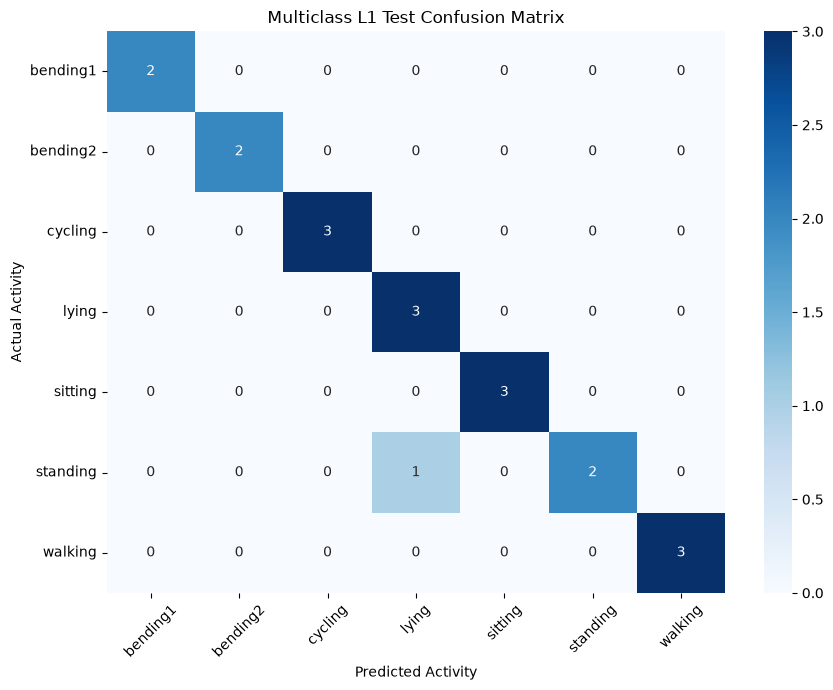

In [52]:
activity_order = best_multi_model.named_steps[
    "classifier"
].classes_

multi_test_matrix = confusion_matrix(
    multi_test_labels,
    multi_test_predictions,
    labels=activity_order
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    multi_test_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=activity_order,
    yticklabels=activity_order
)

plt.xlabel("Predicted Activity")
plt.ylabel("Actual Activity")
plt.title("Multiclass L1 Test Confusion Matrix")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

The multiclass L1 model achieved a test accuracy of 94.74%, corresponding to a test error of 5.26%. It correctly classified 18 of the 19 test instances. The only error occurred when one standing instance was classified as lying. All other test instances were classified correctly.

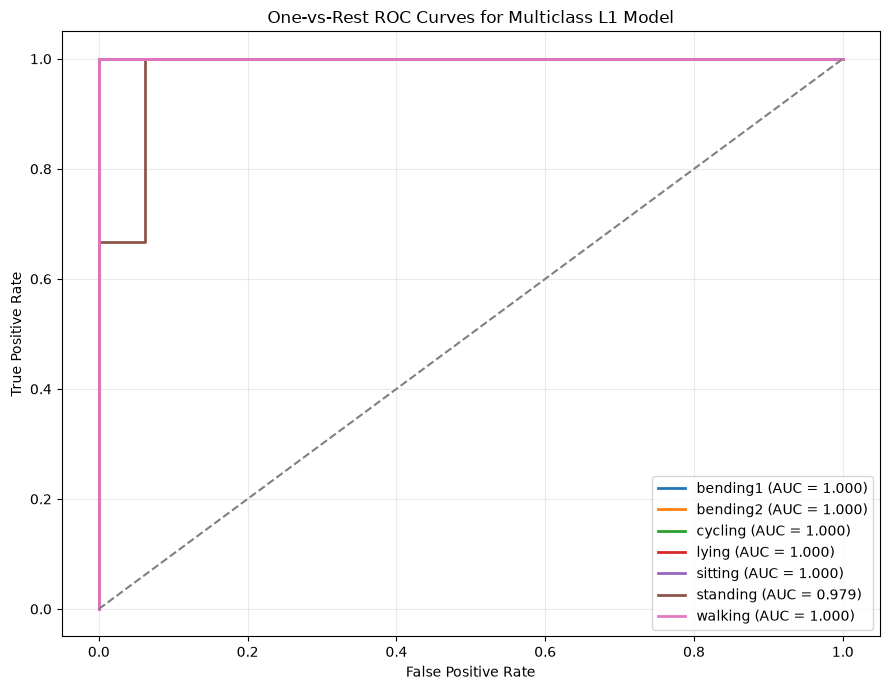

In [53]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import auc

activity_order = best_multi_model.named_steps[
    "classifier"
].classes_

binary_test_labels = label_binarize(
    multi_test_labels,
    classes=activity_order
)

plt.figure(figsize=(9, 7))

class_auc_scores = {}

for class_index, activity_name in enumerate(activity_order):
    class_fpr, class_tpr, _ = roc_curve(
        binary_test_labels[:, class_index],
        multi_test_probabilities[:, class_index]
    )

    class_auc = auc(
        class_fpr,
        class_tpr
    )

    class_auc_scores[activity_name] = class_auc

    plt.plot(
        class_fpr,
        class_tpr,
        linewidth=2,
        label=f"{activity_name} (AUC = {class_auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("One-vs-Rest ROC Curves for Multiclass L1 Model")
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

The one-vs-rest ROC curves show that the model separates most activities very well. Six of the seven activities have an AUC of 1.00. Standing has a slightly lower AUC of 0.979, which agrees with the confusion matrix because one standing instance was classified as lying.

#### 2(c)(ii) Naive Bayes Classification

In [54]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import cross_val_score

nb_search_rows = []

In [55]:
for segment_count in range(1, 21):
    nb_train_table = assemble_segment_table(
        segment_count,
        split_name="train"
    )

    nb_train_features = nb_train_table.drop(
        columns=["activity", "binary_label"]
    )

    nb_train_labels = nb_train_table["activity"]

    gaussian_pipeline = Pipeline([
        ("scale", StandardScaler()),
        ("classifier", GaussianNB())
    ])

    multinomial_pipeline = Pipeline([
        ("scale", MinMaxScaler()),
        ("classifier", MultinomialNB())
    ])

    gaussian_scores = cross_val_score(
        gaussian_pipeline,
        nb_train_features,
        nb_train_labels,
        cv=multi_fold_plan,
        scoring="accuracy"
    )

    multinomial_scores = cross_val_score(
        multinomial_pipeline,
        nb_train_features,
        nb_train_labels,
        cv=multi_fold_plan,
        scoring="accuracy"
    )

    nb_search_rows.append({
        "segments": segment_count,
        "gaussian_cv": gaussian_scores.mean(),
        "multinomial_cv": multinomial_scores.mean()
    })

    print(
        f"Segments: {segment_count:2d} | "
        f"Gaussian: {gaussian_scores.mean():.4f} | "
        f"Multinomial: {multinomial_scores.mean():.4f}"
    )

Segments:  1 | Gaussian: 0.8701 | Multinomial: 0.7533
Segments:  2 | Gaussian: 0.8987 | Multinomial: 0.6953
Segments:  3 | Gaussian: 0.7108 | Multinomial: 0.6667
Segments:  4 | Gaussian: 0.7672 | Multinomial: 0.6961
Segments:  5 | Gaussian: 0.7108 | Multinomial: 0.7533
Segments:  6 | Gaussian: 0.6944 | Multinomial: 0.6953
Segments:  7 | Gaussian: 0.6667 | Multinomial: 0.6806
Segments:  8 | Gaussian: 0.6806 | Multinomial: 0.6806
Segments:  9 | Gaussian: 0.6675 | Multinomial: 0.6667
Segments: 10 | Gaussian: 0.6511 | Multinomial: 0.7394
Segments: 11 | Gaussian: 0.6667 | Multinomial: 0.6667
Segments: 12 | Gaussian: 0.5784 | Multinomial: 0.6814
Segments: 13 | Gaussian: 0.6087 | Multinomial: 0.6814
Segments: 14 | Gaussian: 0.5662 | Multinomial: 0.6520
Segments: 15 | Gaussian: 0.5074 | Multinomial: 0.6667
Segments: 16 | Gaussian: 0.5229 | Multinomial: 0.6814
Segments: 17 | Gaussian: 0.5229 | Multinomial: 0.6520
Segments: 18 | Gaussian: 0.4044 | Multinomial: 0.6667
Segments: 19 | Gaussian: 0.5

In [56]:
nb_search_table = pd.DataFrame(
    nb_search_rows
)

nb_search_table

,segments,gaussian_cv,multinomial_cv
0,1,0.870098,0.753268
1,2,0.898693,0.695261
2,3,0.710784,0.666667
3,4,0.767157,0.696078
4,5,0.710784,0.753268
5,6,0.694444,0.695261
6,7,0.666667,0.680556
7,8,0.680556,0.680556
8,9,0.667484,0.666667
9,10,0.651144,0.739379


In [57]:
best_gaussian_row = nb_search_table.sort_values(
    ["gaussian_cv", "segments"],
    ascending=[False, True]
).iloc[0]

best_multinomial_row = nb_search_table.sort_values(
    ["multinomial_cv", "segments"],
    ascending=[False, True]
).iloc[0]

best_gaussian_segments = int(
    best_gaussian_row["segments"]
)

best_multinomial_segments = int(
    best_multinomial_row["segments"]
)

best_gaussian_cv = float(
    best_gaussian_row["gaussian_cv"]
)

best_multinomial_cv = float(
    best_multinomial_row["multinomial_cv"]
)

print(
    "Best Gaussian segments:",
    best_gaussian_segments
)

print(
    f"Best Gaussian CV accuracy: "
    f"{best_gaussian_cv:.4f}"
)

print(
    "Best Multinomial segments:",
    best_multinomial_segments
)

print(
    f"Best Multinomial CV accuracy: "
    f"{best_multinomial_cv:.4f}"
)

Best Gaussian segments: 2
Best Gaussian CV accuracy: 0.8987
Best Multinomial segments: 1
Best Multinomial CV accuracy: 0.7533


Gaussian Naive Bayes obtained its highest cross-validation accuracy with two segments, while Multinomial Naive Bayes performed best without splitting the time series. Gaussian Naive Bayes had the higher cross-validation accuracy of the two models.

In [58]:
gaussian_train_table = assemble_segment_table(
    best_gaussian_segments,
    split_name="train"
)

gaussian_test_table = assemble_segment_table(
    best_gaussian_segments,
    split_name="test"
)

gaussian_train_features = gaussian_train_table.drop(
    columns=["activity", "binary_label"]
)

gaussian_train_labels = gaussian_train_table["activity"]

gaussian_test_features = gaussian_test_table.drop(
    columns=["activity", "binary_label"]
)

gaussian_test_labels = gaussian_test_table["activity"]

final_gaussian_model = Pipeline([
    ("scale", StandardScaler()),
    ("classifier", GaussianNB())
])

final_gaussian_model.fit(
    gaussian_train_features,
    gaussian_train_labels
)

gaussian_predictions = final_gaussian_model.predict(
    gaussian_test_features
)

gaussian_probabilities = final_gaussian_model.predict_proba(
    gaussian_test_features
)

gaussian_test_accuracy = accuracy_score(
    gaussian_test_labels,
    gaussian_predictions
)

gaussian_test_error = 1 - gaussian_test_accuracy

In [59]:
multinomial_train_table = assemble_segment_table(
    best_multinomial_segments,
    split_name="train"
)

multinomial_test_table = assemble_segment_table(
    best_multinomial_segments,
    split_name="test"
)

multinomial_train_features = multinomial_train_table.drop(
    columns=["activity", "binary_label"]
)

multinomial_train_labels = multinomial_train_table["activity"]

multinomial_test_features = multinomial_test_table.drop(
    columns=["activity", "binary_label"]
)

multinomial_test_labels = multinomial_test_table["activity"]

final_multinomial_model = Pipeline([
    ("scale", MinMaxScaler()),
    ("classifier", MultinomialNB())
])

final_multinomial_model.fit(
    multinomial_train_features,
    multinomial_train_labels
)

multinomial_predictions = final_multinomial_model.predict(
    multinomial_test_features
)

multinomial_probabilities = final_multinomial_model.predict_proba(
    multinomial_test_features
)

multinomial_test_accuracy = accuracy_score(
    multinomial_test_labels,
    multinomial_predictions
)

multinomial_test_error = 1 - multinomial_test_accuracy

In [60]:
print(
    f"Gaussian NB test accuracy: "
    f"{gaussian_test_accuracy:.4f}"
)

print(
    f"Gaussian NB test error: "
    f"{gaussian_test_error:.4f}"
)

print(
    f"Multinomial NB test accuracy: "
    f"{multinomial_test_accuracy:.4f}"
)

print(
    f"Multinomial NB test error: "
    f"{multinomial_test_error:.4f}"
)

Gaussian NB test accuracy: 0.8421
Gaussian NB test error: 0.1579
Multinomial NB test accuracy: 0.6842
Multinomial NB test error: 0.3158


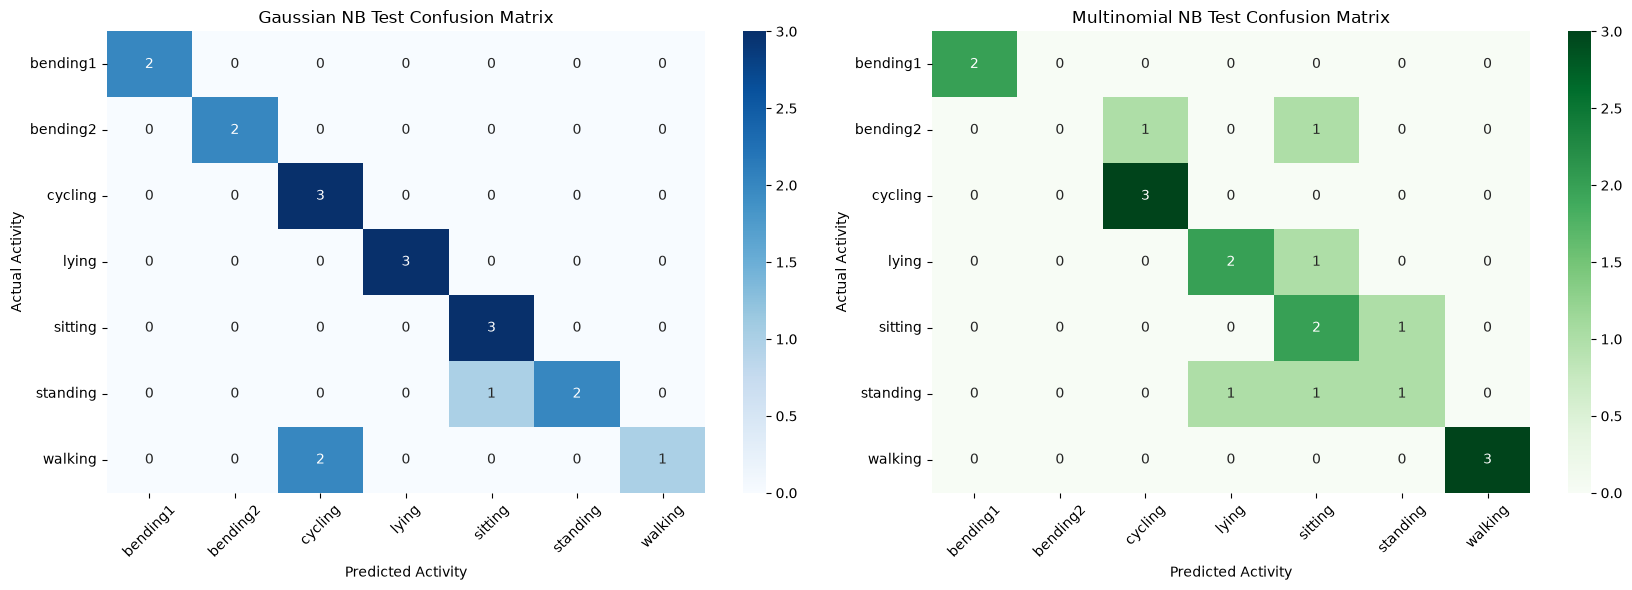

In [61]:
gaussian_class_order = final_gaussian_model.named_steps[
    "classifier"
].classes_

multinomial_class_order = final_multinomial_model.named_steps[
    "classifier"
].classes_

gaussian_matrix = confusion_matrix(
    gaussian_test_labels,
    gaussian_predictions,
    labels=gaussian_class_order
)

multinomial_matrix = confusion_matrix(
    multinomial_test_labels,
    multinomial_predictions,
    labels=multinomial_class_order
)

figure, axes = plt.subplots(
    1,
    2,
    figsize=(17, 6)
)

sns.heatmap(
    gaussian_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=gaussian_class_order,
    yticklabels=gaussian_class_order,
    ax=axes[0]
)

axes[0].set_title("Gaussian NB Test Confusion Matrix")
axes[0].set_xlabel("Predicted Activity")
axes[0].set_ylabel("Actual Activity")
axes[0].tick_params(axis="x", rotation=45)

sns.heatmap(
    multinomial_matrix,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=multinomial_class_order,
    yticklabels=multinomial_class_order,
    ax=axes[1]
)

axes[1].set_title("Multinomial NB Test Confusion Matrix")
axes[1].set_xlabel("Predicted Activity")
axes[1].set_ylabel("Actual Activity")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [62]:
def plot_activity_roc(
    actual_labels,
    probability_values,
    class_names,
    graph_title
):
    binary_labels = label_binarize(
        actual_labels,
        classes=class_names
    )

    auc_values = {}

    plt.figure(figsize=(9, 7))

    for class_index, activity_name in enumerate(class_names):
        activity_fpr, activity_tpr, _ = roc_curve(
            binary_labels[:, class_index],
            probability_values[:, class_index]
        )

        activity_auc = auc(
            activity_fpr,
            activity_tpr
        )

        auc_values[activity_name] = activity_auc

        plt.plot(
            activity_fpr,
            activity_tpr,
            linewidth=2,
            label=(
                f"{activity_name} "
                f"(AUC = {activity_auc:.3f})"
            )
        )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="gray"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(graph_title)
    plt.legend(loc="lower right")
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

    return auc_values

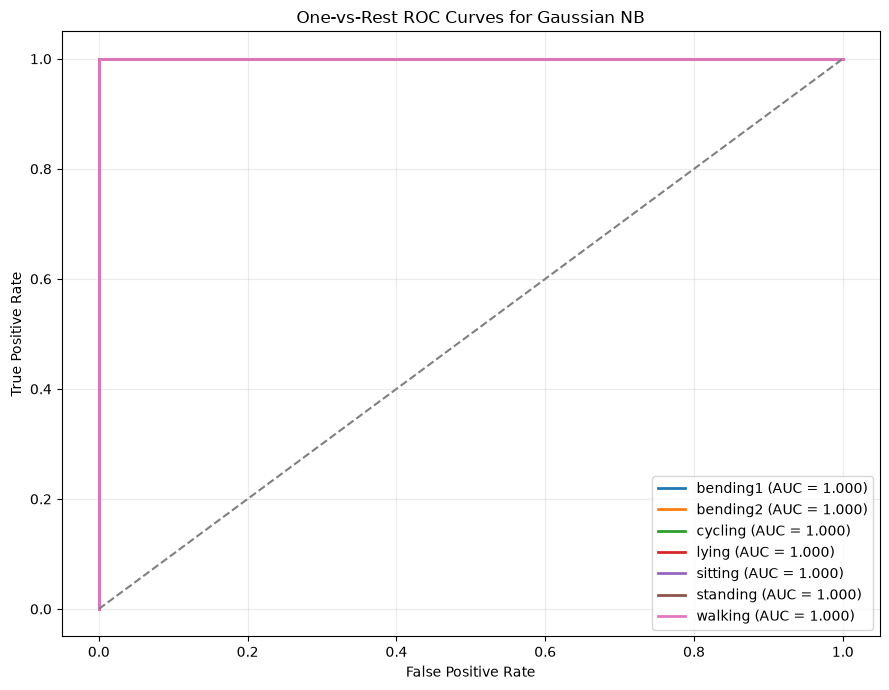

In [63]:
gaussian_auc_values = plot_activity_roc(
    gaussian_test_labels,
    gaussian_probabilities,
    gaussian_class_order,
    "One-vs-Rest ROC Curves for Gaussian NB"
)

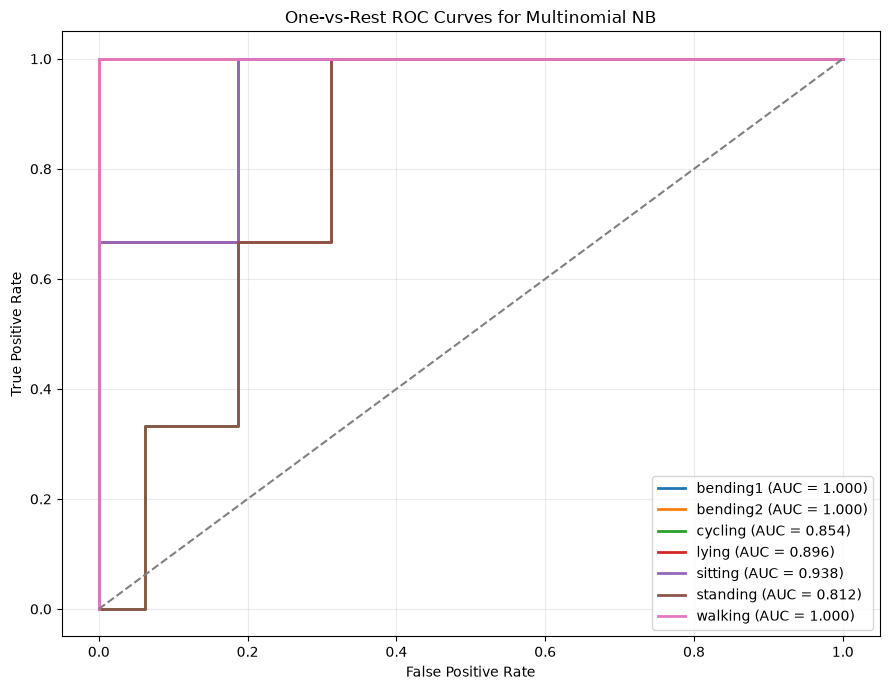

In [64]:
multinomial_auc_values = plot_activity_roc(
    multinomial_test_labels,
    multinomial_probabilities,
    multinomial_class_order,
    "One-vs-Rest ROC Curves for Multinomial NB"
)

Gaussian Naive Bayes achieved a test accuracy of 84.21% and a test error of 15.79%. Multinomial Naive Bayes achieved a lower test accuracy of 68.42%, with a test error of 31.58%. Therefore, Gaussian Naive Bayes performed better than Multinomial Naive Bayes on this dataset.

#### 2(c)(iii) Comparison of Multiclass Models

The L1-penalized logistic regression model performed best, with a test accuracy of 94.74% and a test error of 5.26%. Gaussian Naive Bayes was the second-best model, with an accuracy of 84.21%. Multinomial Naive Bayes had the lowest accuracy at 68.42%.

The L1 model is the best choice for this problem because it produced the lowest test error. Its regularization also allowed it to remove less useful features while keeping the features that were most helpful for separating the seven activities.

## 3. ISLR Exercise 4.8.3

For an observation $X=x$, the Bayes classifier assigns the observation to the class with the largest posterior probability. Therefore, we compare

$$
\pi_k f_k(x),
$$

where $\pi_k$ is the prior probability for class $k$, and

$$
f_k(x)
=
\frac{1}{\sqrt{2\pi}\sigma_k}
\exp\left(
-\frac{(x-\mu_k)^2}{2\sigma_k^2}
\right).
$$

Taking the logarithm does not change which class has the largest value. After removing the term that is common to every class, the discriminant function becomes

$$
\delta_k(x)
=
\log(\pi_k)
-\log(\sigma_k)
-\frac{(x-\mu_k)^2}{2\sigma_k^2}.
$$

Expanding the squared term gives

$$
\delta_k(x)
=
-\frac{x^2}{2\sigma_k^2}
+\frac{\mu_kx}{\sigma_k^2}
-\frac{\mu_k^2}{2\sigma_k^2}
-\log(\sigma_k)
+\log(\pi_k).
$$

This expression contains an $x^2$ term. Since each class can have a different variance, the coefficient of $x^2$ depends on the class and cannot be removed when the discriminant functions are compared.

For example, the decision boundary between classes $k$ and $l$ is found by setting

$$
\delta_k(x)=\delta_l(x).
$$

The resulting equation contains a term of the form

$$
\left(
\frac{1}{2\sigma_l^2}
-
\frac{1}{2\sigma_k^2}
\right)x^2.
$$

Therefore, the decision boundary is generally quadratic. If all classes had the same variance, the quadratic term would cancel and the boundary would be linear. Since QDA allows each class to have a different variance, the Bayes classifier is quadratic rather than linear.

## 4. ISLR Exercise 4.8.7

Let \(D\) represent the event that a company issues a dividend. We are given

$$
P(D)=0.8,
\qquad
P(D^c)=0.2.
$$

The class means and common variance are

$$
\mu_D=10,
\qquad
\mu_{D^c}=0,
\qquad
\sigma^2=36.
$$

Using Bayes' theorem,

$$
P(D\mid X=4)
=
\frac{P(D)f_D(4)}
{P(D)f_D(4)+P(D^c)f_{D^c}(4)}.
$$

Since both classes have the same variance, the common normal-density constant cancels. Therefore,

$$
P(D\mid X=4)
=
\frac{
0.8\exp\left(-\frac{(4-10)^2}{2(36)}\right)
}{
0.8\exp\left(-\frac{(4-10)^2}{2(36)}\right)
+
0.2\exp\left(-\frac{(4-0)^2}{2(36)}\right)
}.
$$

Substituting the values gives

$$
P(D\mid X=4)
=
\frac{
0.8e^{-0.5}
}{
0.8e^{-0.5}+0.2e^{-2/9}
}.
$$

Therefore,

$$
P(D\mid X=4)
\approx 0.7519.
$$

Thus, the probability that the company will issue a dividend is approximately \(75.19\%\).